# 4.0 — HPA model comparison v4

This version uses only **Pearson ≥ 0.50**, **Pearson ≥ 0.70**, **MSE ≤ 0.20**, and **MSE ≤ 0.30**.

The central correction is the denominator. Every HPA percentage is now divided by the **full HPA class size supplied for that class**, rather than by the smaller number of class members that happened to enter a model-specific evaluation universe.

All figures are:

- percentage-based;
- vertical bar plots;
- arranged in compact grids;
- explicit about proteins that were evaluated but not predicted well and proteins that were not evaluated at all.

No `0/0` HPA rows are produced because all 20 reference HPA classes have a strictly positive full-class denominator.

In [3]:
from pathlib import Path
from collections import OrderedDict
import gzip, io, math, os, re, textwrap, warnings, zipfile

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 240)
pd.set_option('display.max_colwidth', 140)

# -----------------------------------------------------------------------------
# Paths
# -----------------------------------------------------------------------------
BASE_DIR = Path.cwd()
DOWNLOAD_DIR = BASE_DIR / 'pan_atlas_downloads'
OUTPUT_DIR = BASE_DIR / '4.0_hpa_v4_outputs'
TABLE_DIR = OUTPUT_DIR / 'tables'
FIGURE_DIR = OUTPUT_DIR / 'figures'
for folder in (OUTPUT_DIR, TABLE_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Manual overrides. Leave empty to use automatic discovery.
CASCADE_LONG_FILES = []
INDEPENDENT_SCORE_FILES = []
AUTO_SEARCH_CASCADE_FILES = True
AUTO_SEARCH_INDEPENDENT_SCORE_FILES = True
MAX_AUTO_SCORE_FILES = 100

DATASET_FILTER = None
SOURCE_ID_FILTER = None
INDEPENDENT_UNIVERSE_MODE = 'union'  # 'union' or 'intersection'
DUPLICATE_SCORE_AGGREGATION = 'median'
REQUIRE_INDEPENDENT_SCORES = False

MODELS = ['Proxy model', 'ElasticNet', 'XGB']
SUCCESS_STAGES = ['Proxy model', 'ElasticNet', 'XGB']
CASCADE_STAGES = ['Proxy model', 'ElasticNet', 'XGB', 'Still not good', 'Other']
SELECTED_THRESHOLDS_BY_METRIC = OrderedDict([
    ('Pearson', [0.50, 0.70]),
    ('MSE', [0.20, 0.30]),
])
PEARSON_THRESHOLDS = [0.50, 0.70]
MSE_THRESHOLDS = [0.20, 0.30]
THRESHOLD_TOLERANCE = 1e-7
METRIC_ORDER = {'Pearson': 0, 'MSE': 1}
MODEL_ORDER_FOR_MARGINAL_GAIN = MODELS.copy()

# Authoritative full HPA class sizes supplied by the user.
HPA_REFERENCE_COUNTS = OrderedDict([
    ('Enzymes', 3777),
    ('Metabolic proteins', 2882),
    ('CD markers', 384),
    ('Blood group antigen proteins', 31),
    ('Nuclear receptors', 49),
    ('Transporters', 2137),
    ('Ribosomal proteins', 180),
    ('G-protein coupled receptors', 743),
    ('Voltage-gated ion channels', 132),
    ('Predicted membrane proteins', 5571),
    ('Predicted secreted proteins', 1902),
    ('Predicted intracellular proteins', 15906),
    ('Plasma proteins', 3750),
    ('Transcription factors', 1485),
    ('RNA polymerase related proteins', 34),
    ('RAS pathway related proteins', 235),
    ('Citric acid cycle related proteins', 30),
    ('Essential proteins', 2022),
    ('Immunoglobulin genes', 214),
    ('T-cell receptor genes', 196),
])
HPA_MACRO_CLASSES = list(HPA_REFERENCE_COUNTS)
HPA_SHORT_LABELS = [
    'Enzymes', 'Metabolic', 'CD markers', 'Blood group', 'Nuclear rec.',
    'Transporters', 'Ribosomal', 'GPCR', 'Voltage-gated', 'Pred. membrane',
    'Pred. secreted', 'Pred. intracellular', 'Plasma', 'TFs',
    'RNA polymerase', 'RAS pathway', 'TCA cycle', 'Essential',
    'Immunoglobulin', 'T-cell receptor'
]

STAGE_COLORS = OrderedDict([
    ('Proxy model', '#4E79A7'),
    ('ElasticNet', '#F28E2B'),
    ('XGB', '#E15759'),
    ('Still not good', '#B07AA1'),
    ('Other', '#9D9D9D'),
])
MODEL_COLORS = {k: STAGE_COLORS[k] for k in MODELS}
FULL_DECOMPOSITION_COLORS = OrderedDict([
    ('Proxy-covered', '#4E79A7'),
    ('ElasticNet additional', '#F28E2B'),
    ('XGB additional', '#E15759'),
    ('Evaluated but not predicted well', '#B07AA1'),
    ('Not evaluated / absent from universe', '#E6E6E6'),
])
MODEL_OVERLAP_COLORS = OrderedDict([
    ('Proxy only', '#4E79A7'),
    ('ElasticNet only', '#F28E2B'),
    ('XGB only', '#E15759'),
    ('Shared by 2 models', '#76B7B2'),
    ('Shared by 3 models', '#59A14F'),
    ('Evaluated, no model covers', '#B07AA1'),
    ('Not evaluated / absent from universe', '#E6E6E6'),
])
PEARSON_MSE_COLORS = OrderedDict([
    ('Pearson only', '#6F4E9C'),
    ('Shared', '#59A14F'),
    ('MSE only', '#E15759'),
    ('Jointly evaluated, neither passes', '#B07AA1'),
    ('Not jointly evaluated', '#E6E6E6'),
])

COMPACT_GRID_MAX_COLS = 2
VERTICAL_PANEL_SIZE = (6.2, 4.2)
VERTICAL_LABEL_ROTATION = 63
BAR_WIDTH = 0.78
SAVE_PNG = True
SAVE_SVG = False
SAVE_PDF = False
DPI = 180
DISPLAY_MAIN_FIGURES = True

mpl.rcParams.update({
    'figure.dpi': 125,
    'savefig.dpi': DPI,
    'font.size': 9.0,
    'axes.titlesize': 10.5,
    'axes.titleweight': 'bold',
    'axes.labelsize': 9.2,
    'xtick.labelsize': 7.2,
    'ytick.labelsize': 7.8,
    'legend.fontsize': 8.0,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

print('Base directory:', BASE_DIR)
print('Output directory:', OUTPUT_DIR)
print('Thresholds:', dict(SELECTED_THRESHOLDS_BY_METRIC))

Base directory: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison
Output directory: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.0_hpa_v4_outputs
Thresholds: {'Pearson': [0.5, 0.7], 'MSE': [0.2, 0.3]}


## Percentage convention used throughout

For each HPA class \(c\), the denominator is the full reference size \(N_c\) shown in the table supplied with the analysis.

For example, if one GPCR is covered by Proxy, the plotted percentage is:

\[
100	imes
rac{1}{743}=0.135\%,
\]

not \(1/1=100\%\). The remaining GPCRs are represented explicitly as evaluated-but-not-covered or not-evaluated.

In [4]:
def safe_filename(text, max_len=180):
    text = re.sub(r'[^A-Za-z0-9._ -]+', '_', str(text))
    text = re.sub(r'\s+', '_', text).strip('._-')
    return (text[:max_len] or 'figure')


def wrap_label(text, width=29):
    return '\n'.join(textwrap.wrap(str(text), width=width, break_long_words=False))


def normalize_text(value):
    value = str(value).strip().replace('–', '-').replace('—', '-').replace('−', '-')
    return re.sub(r'\s+', ' ', value).casefold()


def clean_gene_symbol(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if not value or value.casefold() in {'nan', 'none', 'na', 'null'}:
        return np.nan
    return re.split(r'[;|,/\s]+', value)[0].upper()


def split_hpa_terms(value):
    if pd.isna(value):
        return []
    text = str(value).strip()
    if not text or text.casefold() in {'nan', 'none', 'na', 'null'}:
        return []
    out, seen = [], set()
    for part in re.split(r'[,;|]+', text):
        term = re.sub(r'\s+', ' ', part.strip())
        key = normalize_text(term)
        if term and key not in seen:
            out.append(term)
            seen.add(key)
    return out


def pick_column(df, candidates, required=True):
    norm_to_col = {normalize_text(c): c for c in df.columns}
    for cand in candidates:
        if cand in df.columns:
            return cand
        key = normalize_text(cand)
        if key in norm_to_col:
            return norm_to_col[key]
    for cand in candidates:
        words = normalize_text(cand).split()
        for col in df.columns:
            norm_col = normalize_text(col)
            if words and all(w in norm_col for w in words):
                return col
    if required:
        raise KeyError(f'Could not find any of {candidates}. Columns include: {list(df.columns)[:50]}')
    return None


def read_table_any(path):
    path = Path(path)
    suffixes = [s.lower() for s in path.suffixes]
    if path.suffix.lower() == '.parquet':
        return pd.read_parquet(path)
    if suffixes and suffixes[-1] == '.zip':
        with zipfile.ZipFile(path) as zf:
            names = [n for n in zf.namelist() if not n.endswith('/') and n.lower().endswith(('.tsv', '.txt', '.csv'))]
            if not names:
                raise ValueError(f'No delimited table found inside {path}')
            inner = names[0]
            sep = ',' if inner.lower().endswith('.csv') else '\t'
            with zf.open(inner) as fh:
                return pd.read_csv(fh, sep=sep, dtype=str, low_memory=False)
    if suffixes and suffixes[-1] == '.gz':
        sep = ',' if len(suffixes) >= 2 and suffixes[-2] == '.csv' else '\t'
        return pd.read_csv(path, sep=sep, dtype=str, compression='gzip', low_memory=False)
    if path.suffix.lower() == '.csv':
        return pd.read_csv(path, dtype=str, low_memory=False)
    return pd.read_csv(path, sep='\t', dtype=str, low_memory=False)


def save_figure(fig, stem):
    stem = safe_filename(stem)
    saved = []
    if SAVE_PNG:
        p = FIGURE_DIR / f'{stem}.png'
        fig.savefig(p, bbox_inches='tight', dpi=DPI)
        saved.append(p)
    if SAVE_SVG:
        p = FIGURE_DIR / f'{stem}.svg'
        fig.savefig(p, bbox_inches='tight')
        saved.append(p)
    if SAVE_PDF:
        p = FIGURE_DIR / f'{stem}.pdf'
        fig.savefig(p, bbox_inches='tight')
        saved.append(p)
    return saved


def apply_grid_axis_label_policy(fig):
    """Avoid repeated axis titles in multi-column subplot grids.

    For two-column grids, keep the y-axis title only on the left panel of
    each row and the x-axis title only on the right panel of each row.
    Tick labels are left unchanged.
    """
    for ax in fig.axes:
        if not ax.get_visible():
            continue
        try:
            spec = ax.get_subplotspec()
            grid = spec.get_gridspec()
        except Exception:
            continue
        if grid.ncols <= 1:
            continue
        col = spec.colspan.start
        if col != 0:
            ax.set_ylabel('')
        if col != grid.ncols - 1:
            ax.set_xlabel('')


def finish_figure(fig, stem, show=False):
    apply_grid_axis_label_policy(fig)
    save_figure(fig, stem)
    if show:
        plt.show()
    else:
        plt.close(fig)


def safe_percent(numerator, denominator):
    n = np.asarray(numerator, dtype=float)
    d = np.asarray(denominator, dtype=float)
    out = np.zeros(np.broadcast(n, d).shape, dtype=float)
    np.divide(100.0 * n, d, out=out, where=d > 0)
    return out


def canonical_stage_group(raw_stage):
    text = normalize_text(raw_stage)
    if not text or text in {'nan', 'none'}:
        return 'Other'
    if 'still' in text and 'good' in text:
        return 'Still not good'
    if 'no valid mse' in text:
        return 'Still not good'
    if 'proxy' in text:
        return 'Proxy model'
    if 'enet' in text or 'elastic' in text:
        return 'ElasticNet'
    if 'xgb' in text or 'xgboost' in text:
        return 'XGB'
    return 'Other'


def canonical_model(value):
    text = normalize_text(value)
    if not text or text in {'nan', 'none'}:
        return None
    if 'proxy' in text:
        return 'Proxy model'
    if 'enet' in text or 'elastic' in text:
        return 'ElasticNet'
    if 'xgb' in text or 'xgboost' in text or 'boosted tree' in text:
        return 'XGB'
    return None


def parse_metric_family(*values):
    text = ' '.join(str(v) for v in values).casefold()
    if 'pearson' in text or re.search(r'(^|[^a-z])pcc([^a-z]|$)', text):
        return 'Pearson'
    if 'cosine' in text or 'cos sim' in text or 'cos_sim' in text:
        return 'Cosine'
    if 'mean squared error' in text or re.search(r'(^|[^a-z])mse([^a-z]|$)', text):
        return 'MSE'
    return None


def parse_threshold_value(row):
    for col in ['threshold', 'prediction_threshold', 'corr_threshold', 'mse_threshold', 'metric_threshold']:
        if col in row.index and pd.notna(row[col]):
            try:
                value = float(str(row[col]).strip())
                if math.isfinite(value):
                    return value
            except Exception:
                pass
    label = str(row.get('threshold_label', ''))
    nums = re.findall(r'[-+]?\d*\.\d+|[-+]?\d+', label)
    if not nums:
        return np.nan
    value = float(nums[-1])
    metric = parse_metric_family(row.get('analysis', ''), label)
    if metric in {'Pearson', 'Cosine'} and 1 < value <= 100:
        value /= 100.0
    return value


def threshold_operator(metric):
    return '<=' if metric == 'MSE' else '>='


def threshold_label(metric, value):
    return f'{metric} {threshold_operator(metric)} {float(value):.2f}'


def passes_threshold(values, metric, threshold):
    values = pd.to_numeric(values, errors='coerce')
    return values.le(threshold) if metric == 'MSE' else values.ge(threshold)


def preferred_analysis_rank(analysis, metric):
    a = normalize_text(analysis)
    if metric == 'Pearson':
        if a == 'pearson_threshold_sweep': return 0
        if a == 'main_pearson_cascade': return 1
        if 'pearson' in a and 'threshold' in a: return 2
        if 'pearson' in a: return 3
    if metric == 'Cosine':
        if a == 'cosine_threshold_sweep': return 0
        if a == 'main_cosine_cascade': return 1
        if 'cosine' in a and 'threshold' in a: return 2
        if 'cosine' in a: return 3
    if metric == 'MSE':
        if a == 'mse_threshold_sweep': return 0
        if a == 'main_mse_cascade': return 1
        if 'mse' in a and 'threshold' in a and 'percentile' not in a: return 2
        if 'mse' in a: return 3
    return 99


def infer_source_id(path):
    p = Path(path)
    parts = [x.lower() for x in p.parts]
    if 'procedural_proxy_z_tables' in parts:
        return 'proxy_z'
    if 'procedural_proxy_norm_tables' in parts:
        return 'proxy_linear'
    if 'procedural_tables' in parts:
        return 'procedural'
    for part in reversed(p.parts):
        if part.endswith('_tables') or part.startswith('procedural'):
            return safe_filename(part)
    return safe_filename(p.parent.parent.name if len(p.parts) >= 3 else p.parent.name)


def ordered_cases(df):
    cols = ['case_id', 'context_id', 'source_id', 'dataset', 'metric_family', 'threshold_value', 'case_label']
    out = df[[c for c in cols if c in df.columns]].drop_duplicates().copy()
    out['metric_order'] = out['metric_family'].map(METRIC_ORDER).fillna(99)
    return out.sort_values(['context_id', 'metric_order', 'threshold_value']).drop(columns='metric_order')


def compact_grid(n_panels, panel_size=(3.75, 5.35), max_cols=None, **subplot_kwargs):
    """Create a compact grid and hide unused axes."""
    n_panels = int(n_panels)
    if n_panels < 1:
        raise ValueError('n_panels must be at least 1')
    max_cols = COMPACT_GRID_MAX_COLS if max_cols is None else max_cols
    ncols = min(max_cols, n_panels)
    nrows = int(math.ceil(n_panels / ncols))
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(panel_size[0] * ncols, panel_size[1] * nrows),
        squeeze=False,
        **subplot_kwargs,
    )
    flat = axes.ravel()
    for ax in flat[n_panels:]:
        ax.set_visible(False)
    return fig, flat[:n_panels], nrows, ncols


def set_hpa_axis_labels(ax, orientation='horizontal', show_labels=True):
    positions = np.arange(len(HPA_MACRO_CLASSES))
    if orientation == 'horizontal':
        ax.set_yticks(positions)
        ax.set_yticklabels([wrap_label(x, 24) for x in HPA_MACRO_CLASSES] if show_labels else [])
        if show_labels:
            ax.set_ylabel('HPA macro group')
        ax.invert_yaxis()
    else:
        ax.set_xticks(positions)
        ax.set_xticklabels(
            HPA_SHORT_LABELS if show_labels else [],
            rotation=VERTICAL_LABEL_ROTATION,
            ha='right',
        )
        if show_labels:
            ax.set_xlabel('HPA macro group')


def add_zero_denominator_background(ax, zero_mask, orientation='horizontal', extent=100):
    """Mark undefined 0/0 HPA groups explicitly instead of leaving white space."""
    zero_mask = np.asarray(zero_mask, dtype=bool)
    positions = np.arange(len(zero_mask))
    if orientation == 'horizontal':
        if zero_mask.any():
            ax.barh(
                positions[zero_mask], np.repeat(extent, zero_mask.sum()),
                color='#F2F2F2', edgecolor='#BDBDBD', hatch='///',
                height=BAR_HEIGHT, linewidth=0.5, zorder=0,
            )
        for pos in positions[zero_mask]:
            ax.text(extent / 2, pos, '0/0', ha='center', va='center', fontsize=6.8, color='#555555', zorder=4)
    else:
        for pos in positions[zero_mask]:
            ax.axvspan(pos - 0.42, pos + 0.42, color='#F2F2F2', hatch='///', edgecolor='#BDBDBD', linewidth=0.4, zorder=0)
            ax.text(pos, extent * 0.5, '0/0', ha='center', va='center', rotation=90, fontsize=6.5, color='#555555', zorder=4)


def label_stacked_segment(ax, orientation, base, value, position, text, threshold):
    if not SHOW_SEGMENT_LABELS or value < threshold or value <= 0:
        return
    if orientation == 'horizontal':
        ax.text(base + value / 2, position, text, ha='center', va='center', fontsize=6.2, color='white', fontweight='bold')
    else:
        ax.text(position, base + value / 2, text, ha='center', va='center', fontsize=5.8, color='white', fontweight='bold', rotation=90)


def ordered_independent_cases():
    out = independent_cases.copy()
    out['metric_order'] = out['metric_family'].map(METRIC_ORDER).fillna(99)
    return out.sort_values(['metric_order', 'threshold_value']).drop(columns='metric_order')


HPA_SHORT_MAP = dict(zip(HPA_MACRO_CLASSES, HPA_SHORT_LABELS))


def short_hpa_labels(classes):
    return [HPA_SHORT_MAP.get(str(c), str(c)) for c in classes]


def set_hpa_axis_labels_dynamic(ax, classes, orientation='horizontal', show_labels=True):
    classes = [str(c) for c in classes]
    positions = np.arange(len(classes))
    if orientation == 'horizontal':
        ax.set_yticks(positions)
        ax.set_yticklabels([wrap_label(x, 24) for x in classes] if show_labels else [])
        if show_labels:
            ax.set_ylabel('HPA macro group')
        ax.invert_yaxis()
    else:
        ax.set_xticks(positions)
        ax.set_xticklabels(
            short_hpa_labels(classes) if show_labels else [],
            rotation=VERTICAL_LABEL_ROTATION,
            ha='right',
        )
        if show_labels:
            ax.set_xlabel('HPA macro group')


def probability_zero_overlap(n_universe, n_a, n_b):
    """P(|A∩B|=0) for two random sets of fixed sizes in one universe."""
    n_universe, n_a, n_b = map(int, (n_universe, n_a, n_b))
    if n_universe <= 0 or n_a < 0 or n_b < 0 or n_a > n_universe or n_b > n_universe:
        return np.nan
    if n_a + n_b > n_universe:
        return 0.0
    # log-combinations avoid integer overflow for large protein universes.
    log_p = (
        math.lgamma(n_universe - n_a + 1)
        - math.lgamma(n_b + 1)
        - math.lgamma(n_universe - n_a - n_b + 1)
        - math.lgamma(n_universe + 1)
        + math.lgamma(n_b + 1)
        + math.lgamma(n_universe - n_b + 1)
    )
    return float(math.exp(log_p))


def zero_overlap_diagnosis(n_universe, n_a, n_b, n_shared, p_zero):
    if n_universe == 0:
        return 'No common evaluated universe: overlap is not interpretable.'
    if n_a == 0 or n_b == 0:
        return 'One selected set is empty: zero overlap is automatic.'
    if n_shared > 0:
        return 'The selected sets overlap; use Jaccard and class composition to quantify disagreement.'
    if pd.notna(p_zero) and p_zero < 1e-6:
        return 'Exact zero is extremely unlikely for random sets of these sizes; audit partition construction, identifiers, preprocessing, and threshold logic first.'
    if pd.notna(p_zero) and p_zero < 0.05:
        return 'Exact zero is statistically unusual for sets of these sizes; technical separation is more plausible than chance alone.'
    return 'Exact zero is possible at this selectivity, but still requires universe and pipeline checks before biological interpretation.'

## Load HPA membership and validate the supplied full-class denominators

The supplied class sizes are used as the plotting denominators. The loaded Protein Atlas file is used to map individual gene symbols to the 20 macroclasses. The validation table below makes any HPA-version or identifier discrepancy visible instead of silently changing the denominator.

In [5]:
HPA_CANDIDATE_FILES = [
    DOWNLOAD_DIR / 'hpa_proteinatlas.tsv.zip', DOWNLOAD_DIR / 'proteinatlas.tsv.zip',
    DOWNLOAD_DIR / 'hpa_proteinatlas.tsv.gz', DOWNLOAD_DIR / 'proteinatlas.tsv.gz',
    DOWNLOAD_DIR / 'hpa_proteinatlas.tsv', DOWNLOAD_DIR / 'proteinatlas.tsv',
    BASE_DIR / 'hpa_proteinatlas.tsv.zip', BASE_DIR / 'proteinatlas.tsv.zip',
    BASE_DIR / 'hpa_proteinatlas.tsv', BASE_DIR / 'proteinatlas.tsv',
]
if not any(p.exists() for p in HPA_CANDIDATE_FILES):
    HPA_CANDIDATE_FILES.extend(sorted(
        [p for p in BASE_DIR.rglob('*proteinatlas*') if p.is_file() and p.suffix.lower() in {'.zip', '.gz', '.tsv', '.csv'}],
        key=lambda p: len(p.parts)
    ))

hpa_path = next((p for p in HPA_CANDIDATE_FILES if p.exists()), None)
if hpa_path is None:
    raise FileNotFoundError('HPA file not found. Put proteinatlas.tsv(.zip/.gz) under the project root or pan_atlas_downloads/.')

hpa_raw = read_table_any(hpa_path)
gene_col = pick_column(hpa_raw, ['Gene', 'gene', 'Gene name', 'Gene symbol', 'gene_symbol', 'Gene name according to HGNC'])
protein_class_col = pick_column(hpa_raw, ['Protein class', 'protein_class', 'Protein classes'])

macro_map = {normalize_text(x): x for x in HPA_MACRO_CLASSES}
rows = []
for gene, protein_class in zip(hpa_raw[gene_col], hpa_raw[protein_class_col]):
    g = clean_gene_symbol(gene)
    if pd.isna(g):
        continue
    for term in split_hpa_terms(protein_class):
        macro_class = macro_map.get(normalize_text(term))
        if macro_class is not None:
            rows.append((g, macro_class))

hpa_macro = pd.DataFrame(rows, columns=['gene_symbol', 'hpa_macro_class']).drop_duplicates()
if hpa_macro.empty:
    raise ValueError('No configured HPA macro classes matched the Protein class column.')
hpa_macro['hpa_macro_class'] = pd.Categorical(hpa_macro['hpa_macro_class'], categories=HPA_MACRO_CLASSES, ordered=True)
hpa_macro = hpa_macro.sort_values(['hpa_macro_class', 'gene_symbol']).reset_index(drop=True)
hpa_macro.to_csv(TABLE_DIR / 'hpa_macro_class_membership_long.csv', index=False)

hpa_reference = pd.DataFrame({
    'hpa_macro_class': HPA_MACRO_CLASSES,
    'n_hpa_genes': [HPA_REFERENCE_COUNTS[c] for c in HPA_MACRO_CLASSES],
})
hpa_loaded_counts = (
    hpa_macro.groupby('hpa_macro_class', observed=False)['gene_symbol']
    .nunique().reindex(HPA_MACRO_CLASSES, fill_value=0)
    .rename('n_hpa_genes_in_loaded_file').reset_index()
)
hpa_denominator_validation = hpa_reference.merge(hpa_loaded_counts, on='hpa_macro_class', how='left')
hpa_denominator_validation['loaded_minus_reference'] = (
    hpa_denominator_validation['n_hpa_genes_in_loaded_file'] - hpa_denominator_validation['n_hpa_genes']
)
hpa_denominator_validation.to_csv(TABLE_DIR / 'hpa_reference_denominator_validation.csv', index=False)

print('HPA file:', hpa_path)
print(f'Unique mapped genes in the 20 retained classes: {hpa_macro.gene_symbol.nunique():,}')
display(hpa_denominator_validation)

if (hpa_denominator_validation['loaded_minus_reference'] > 0).any():
    display(Markdown(
        '**Warning:** the loaded HPA file contains more unique members than the supplied reference count for at least one class. '
        'Before interpreting percentages, reconcile the HPA release and identifier-cleaning rules. The notebook will stop if an evaluated count exceeds its reference denominator.'
    ))

HPA file: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\pan_atlas_downloads\hpa_proteinatlas.tsv.zip
Unique mapped genes in the 20 retained classes: 20,151


,hpa_macro_class,n_hpa_genes,n_hpa_genes_in_loaded_file,loaded_minus_reference
0,Enzymes,3777,3777,0
1,Metabolic proteins,2882,2882,0
2,CD markers,384,384,0
3,Blood group antigen proteins,31,31,0
4,Nuclear receptors,49,49,0
5,Transporters,2137,2137,0
6,Ribosomal proteins,180,180,0
7,G-protein coupled receptors,743,743,0
8,Voltage-gated ion channels,132,132,0
9,Predicted membrane proteins,5571,5571,0


# Part 1 — Sequential cascade with full-HPA denominators

In [6]:
EXCLUDED_SOURCE_IDS = {'procedural', 'proxy_linear'}
EXCLUDED_PATH_KEYWORDS = {'procedural_tables', 'procedural_proxy_norm_tables'}


def find_cascade_long_files():
    files = [Path(p) for p in CASCADE_LONG_FILES if Path(p).exists()]
    if AUTO_SEARCH_CASCADE_FILES:
        standard = [
            BASE_DIR / 'procedural_proxy_z_tables' / 'protein_names_by_cascade_partition' / 'cascade_partition_proteins_long.csv',
            BASE_DIR / 'protein_names_by_cascade_partition' / 'cascade_partition_proteins_long.csv',
        ]
        files.extend([p for p in standard if p.exists()])
        files.extend(BASE_DIR.rglob('protein_names_by_cascade_partition/cascade_partition_proteins_long.csv'))
    out, seen = [], set()
    for p in files:
        sid = infer_source_id(p)
        path_text = str(p).lower()
        if sid in EXCLUDED_SOURCE_IDS or any(k in path_text for k in EXCLUDED_PATH_KEYWORDS):
            continue
        rp = p.resolve()
        if rp not in seen:
            out.append(p)
            seen.add(rp)
    return out


cascade_files = find_cascade_long_files()
if not cascade_files:
    raise FileNotFoundError('No cascade_partition_proteins_long.csv was found. Set CASCADE_LONG_FILES in the configuration cell.')

parts = []
for path in cascade_files:
    df = pd.read_csv(path, dtype=str, low_memory=False)
    df['source_path'] = str(path)
    df['source_id'] = infer_source_id(path)
    parts.append(df)
raw_partitions = pd.concat(parts, ignore_index=True, sort=False)

for required in ['protein', 'stage']:
    if required not in raw_partitions.columns:
        raise KeyError(f'Cascade export is missing required column: {required}')
for col, default in [('dataset', 'dataset'), ('analysis', 'analysis_unknown'), ('threshold_label', '')]:
    if col not in raw_partitions.columns:
        raw_partitions[col] = default

partitions = raw_partitions.copy()
partitions['gene_symbol'] = partitions['protein'].apply(clean_gene_symbol)
partitions = partitions.dropna(subset=['gene_symbol']).copy()
partitions['stage_group'] = partitions['stage'].apply(canonical_stage_group)
partitions['metric_family'] = partitions.apply(
    lambda r: parse_metric_family(r.get('analysis', ''), r.get('threshold_label', '')), axis=1
)
partitions['threshold_value'] = partitions.apply(parse_threshold_value, axis=1)
partitions['threshold_value'] = pd.to_numeric(partitions['threshold_value'], errors='coerce').round(2)

if DATASET_FILTER is not None:
    partitions = partitions[partitions['dataset'].astype(str).eq(str(DATASET_FILTER))].copy()
if SOURCE_ID_FILTER is not None:
    partitions = partitions[partitions['source_id'].astype(str).eq(str(SOURCE_ID_FILTER))].copy()

mask = pd.Series(False, index=partitions.index)
for metric, thresholds in SELECTED_THRESHOLDS_BY_METRIC.items():
    metric_mask = partitions['metric_family'].eq(metric)
    threshold_mask = pd.Series(False, index=partitions.index)
    for threshold in thresholds:
        threshold_mask |= np.isclose(partitions['threshold_value'].astype(float), threshold, atol=THRESHOLD_TOLERANCE, equal_nan=False)
    mask |= metric_mask & threshold_mask
selected = partitions[mask].copy()
if selected.empty:
    raise ValueError('No cascade rows matched Pearson 0.50/0.70 or MSE 0.20/0.30.')

selected['analysis_rank'] = selected.apply(lambda r: preferred_analysis_rank(r['analysis'], r['metric_family']), axis=1)
rank_cols = ['source_id', 'dataset', 'metric_family', 'threshold_value']
best_rank = selected.groupby(rank_cols, dropna=False)['analysis_rank'].transform('min')
selected = selected[selected['analysis_rank'].eq(best_rank)].copy()

selected['context_id'] = selected['source_id'].astype(str) + '__' + selected['dataset'].astype(str)
multiple_contexts = selected['context_id'].nunique() > 1
selected['case_id'] = selected.apply(
    lambda r: safe_filename(f"{r['context_id']}__{r['metric_family']}__{r['threshold_value']:.2f}"), axis=1
)
selected['case_label'] = selected.apply(
    lambda r: (
        f"{r['source_id']} | {r['dataset']} | {threshold_label(r['metric_family'], r['threshold_value'])}"
        if multiple_contexts else threshold_label(r['metric_family'], r['threshold_value'])
    ), axis=1
)

partition_key = ['case_id', 'gene_symbol']
stage_multiplicity = selected.groupby(partition_key)['stage_group'].nunique()
ambiguous = stage_multiplicity[stage_multiplicity > 1]
if len(ambiguous):
    print(f'Warning: {len(ambiguous):,} case/gene pairs occur in more than one stage. Keeping the earliest cascade stage.')
    stage_rank = {stage: i for i, stage in enumerate(CASCADE_STAGES)}
    selected['stage_rank'] = selected['stage_group'].map(stage_rank).fillna(999)
    selected = selected.sort_values(partition_key + ['stage_rank']).drop_duplicates(partition_key, keep='first')
else:
    selected = selected.drop_duplicates(partition_key + ['stage_group'])

selected.to_csv(TABLE_DIR / 'part1_selected_cascade_partitions.csv', index=False)
print('Cascade files:')
for path in cascade_files:
    print(' -', path)
print(f'Rows after threshold selection: {len(selected):,}')
display(ordered_cases(selected))

Cascade files:
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\procedural_proxy_z_tables\protein_names_by_cascade_partition\cascade_partition_proteins_long.csv
Rows after threshold selection: 20,452


,case_id,context_id,source_id,dataset,metric_family,threshold_value,case_label
306780,proxy_z__CCLE__Pearson__0.50,proxy_z__CCLE,proxy_z,CCLE,Pearson,0.5,Pearson >= 0.50
327232,proxy_z__CCLE__Pearson__0.70,proxy_z__CCLE,proxy_z,CCLE,Pearson,0.7,Pearson >= 0.70
163616,proxy_z__CCLE__MSE__0.20,proxy_z__CCLE,proxy_z,CCLE,MSE,0.2,MSE <= 0.20
173842,proxy_z__CCLE__MSE__0.30,proxy_z__CCLE,proxy_z,CCLE,MSE,0.3,MSE <= 0.30


## HPA groups inside each threshold-set universe

For every retained threshold case, the notebook now displays a compact table with exactly two columns:

1. `hpa_macro_class`;
2. `n_genes_in_threshold_universe`.

The count is the number of unique genes belonging to that HPA macro class that are present in the evaluated universe for that threshold set. The complete audit table, including the full HPA denominator, percentages, and absent counts, is still exported to `part1_full_hpa_vs_case_universe_long.csv`.


In [7]:
CASE_COLS = ['case_id', 'context_id', 'source_id', 'dataset', 'metric_family', 'threshold_value', 'case_label']
case_table = ordered_cases(selected)
case_class_grid = (
    case_table.assign(_key=1)
    .merge(hpa_reference.assign(_key=1), on='_key')
    .drop(columns='_key')
    .merge(hpa_loaded_counts, on='hpa_macro_class', how='left')
)
case_universe = selected[CASE_COLS + ['gene_symbol']].drop_duplicates()
case_macro = case_universe.merge(hpa_macro, on='gene_symbol', how='inner')
case_evaluated_counts = (
    case_macro.groupby(CASE_COLS + ['hpa_macro_class'], observed=True)['gene_symbol']
    .nunique().reset_index(name='n_hpa_genes_in_evaluated_universe')
)
case_hpa_universe = case_class_grid.merge(
    case_evaluated_counts, on=CASE_COLS + ['hpa_macro_class'], how='left'
)
case_hpa_universe['n_hpa_genes_in_evaluated_universe'] = case_hpa_universe['n_hpa_genes_in_evaluated_universe'].fillna(0).astype(int)
case_hpa_universe['pct_full_hpa_in_evaluated_universe'] = safe_percent(
    case_hpa_universe['n_hpa_genes_in_evaluated_universe'], case_hpa_universe['n_hpa_genes']
)
case_hpa_universe['n_hpa_genes_not_in_evaluated_universe'] = (
    case_hpa_universe['n_hpa_genes'] - case_hpa_universe['n_hpa_genes_in_evaluated_universe']
)

impossible = case_hpa_universe[case_hpa_universe['n_hpa_genes_not_in_evaluated_universe'] < 0]
if len(impossible):
    display(impossible[['case_label', 'hpa_macro_class', 'n_hpa_genes', 'n_hpa_genes_in_evaluated_universe']])
    raise ValueError(
        'At least one evaluated HPA count exceeds the supplied full-class denominator. '
        'Reconcile the HPA release, aliases, and deduplication before plotting percentages.'
    )

case_hpa_universe.to_csv(TABLE_DIR / 'part1_full_hpa_vs_case_universe_long.csv', index=False)


threshold_universe_group_counts = (
    case_hpa_universe[
        CASE_COLS + ['hpa_macro_class', 'n_hpa_genes_in_evaluated_universe']
    ]
    .rename(columns={
        'n_hpa_genes_in_evaluated_universe': 'n_genes_in_threshold_universe'
    })
    .copy()
)
threshold_universe_group_counts.to_csv(
    TABLE_DIR / 'part1_hpa_group_counts_by_threshold_universe.csv', index=False
)

for case in case_table.itertuples(index=False):
    two_col = (
        threshold_universe_group_counts[
            threshold_universe_group_counts['case_id'].eq(case.case_id)
        ][['hpa_macro_class', 'n_genes_in_threshold_universe']]
        .set_index('hpa_macro_class')
        .reindex(HPA_MACRO_CLASSES, fill_value=0)
        .reset_index()
    )
    two_col['n_genes_in_threshold_universe'] = (
        two_col['n_genes_in_threshold_universe'].fillna(0).astype(int)
    )
    display(Markdown(
        f"### Threshold universe — `{case.context_id}` — {case.case_label}"
    ))
    display(two_col.style.hide(axis='index').format({
        'n_genes_in_threshold_universe': '{:,}'
    }))


### Threshold universe — `proxy_z__CCLE` — Pearson >= 0.50

hpa_macro_class,n_genes_in_threshold_universe
Enzymes,"1,360"
Metabolic proteins,"1,040"
CD markers,66
Blood group antigen proteins,5
Nuclear receptors,3
Transporters,535
Ribosomal proteins,145
G-protein coupled receptors,1
Voltage-gated ion channels,0
Predicted membrane proteins,807


### Threshold universe — `proxy_z__CCLE` — Pearson >= 0.70

hpa_macro_class,n_genes_in_threshold_universe
Enzymes,"1,360"
Metabolic proteins,"1,040"
CD markers,66
Blood group antigen proteins,5
Nuclear receptors,3
Transporters,535
Ribosomal proteins,145
G-protein coupled receptors,1
Voltage-gated ion channels,0
Predicted membrane proteins,807


### Threshold universe — `proxy_z__CCLE` — MSE <= 0.20

hpa_macro_class,n_genes_in_threshold_universe
Enzymes,"1,360"
Metabolic proteins,"1,040"
CD markers,66
Blood group antigen proteins,5
Nuclear receptors,3
Transporters,535
Ribosomal proteins,145
G-protein coupled receptors,1
Voltage-gated ion channels,0
Predicted membrane proteins,807


### Threshold universe — `proxy_z__CCLE` — MSE <= 0.30

hpa_macro_class,n_genes_in_threshold_universe
Enzymes,"1,360"
Metabolic proteins,"1,040"
CD markers,66
Blood group antigen proteins,5
Nuclear receptors,3
Transporters,535
Ribosomal proteins,145
G-protein coupled receptors,1
Voltage-gated ion channels,0
Predicted membrane proteins,807


## Corrected sequential percentage decomposition

In [8]:
SEQUENTIAL_COMPONENTS = list(FULL_DECOMPOSITION_COLORS)
stage_to_component = {
    'Proxy model': 'Proxy-covered',
    'ElasticNet': 'ElasticNet additional',
    'XGB': 'XGB additional',
    'Still not good': 'Evaluated but not predicted well',
    'Other': 'Evaluated but not predicted well',
}

stage_macro = (
    selected[CASE_COLS + ['stage_group', 'gene_symbol']].drop_duplicates()
    .merge(hpa_macro, on='gene_symbol', how='inner')
)
stage_macro['component'] = stage_macro['stage_group'].map(stage_to_component)
stage_component_counts = (
    stage_macro.groupby(CASE_COLS + ['hpa_macro_class', 'component'], observed=True)['gene_symbol']
    .nunique().reset_index(name='n_genes')
)

base_case_class = case_hpa_universe[
    CASE_COLS + ['hpa_macro_class', 'n_hpa_genes', 'n_hpa_genes_in_loaded_file',
                 'n_hpa_genes_in_evaluated_universe', 'n_hpa_genes_not_in_evaluated_universe']
].drop_duplicates()
component_grid = (
    base_case_class.assign(_key=1)
    .merge(pd.DataFrame({'component': SEQUENTIAL_COMPONENTS, '_key': 1}), on='_key')
    .drop(columns='_key')
)
sequential_full_hpa = component_grid.merge(
    stage_component_counts,
    on=CASE_COLS + ['hpa_macro_class', 'component'],
    how='left'
)
sequential_full_hpa['n_genes'] = sequential_full_hpa['n_genes'].fillna(0).astype(int)
not_eval_mask = sequential_full_hpa['component'].eq('Not evaluated / absent from universe')
sequential_full_hpa.loc[not_eval_mask, 'n_genes'] = sequential_full_hpa.loc[
    not_eval_mask, 'n_hpa_genes_not_in_evaluated_universe'
].astype(int)
sequential_full_hpa['pct_of_full_hpa_class'] = safe_percent(
    sequential_full_hpa['n_genes'], sequential_full_hpa['n_hpa_genes']
)
sequential_full_hpa['hpa_macro_class'] = pd.Categorical(
    sequential_full_hpa['hpa_macro_class'], categories=HPA_MACRO_CLASSES, ordered=True
)

validation = (
    sequential_full_hpa.groupby(CASE_COLS + ['hpa_macro_class', 'n_hpa_genes'], observed=True)['n_genes']
    .sum().reset_index(name='component_sum')
)
validation['difference_from_full_hpa'] = validation['component_sum'] - validation['n_hpa_genes']
if validation['difference_from_full_hpa'].ne(0).any():
    display(validation[validation['difference_from_full_hpa'].ne(0)])
    raise ValueError('Sequential decomposition does not sum to the full HPA denominator.')

sequential_full_hpa.to_csv(TABLE_DIR / 'part1_sequential_full_hpa_percentage_decomposition.csv', index=False)
print('All sequential class decompositions sum exactly to 100% of the supplied full HPA class size.')

All sequential class decompositions sum exactly to 100% of the supplied full HPA class size.


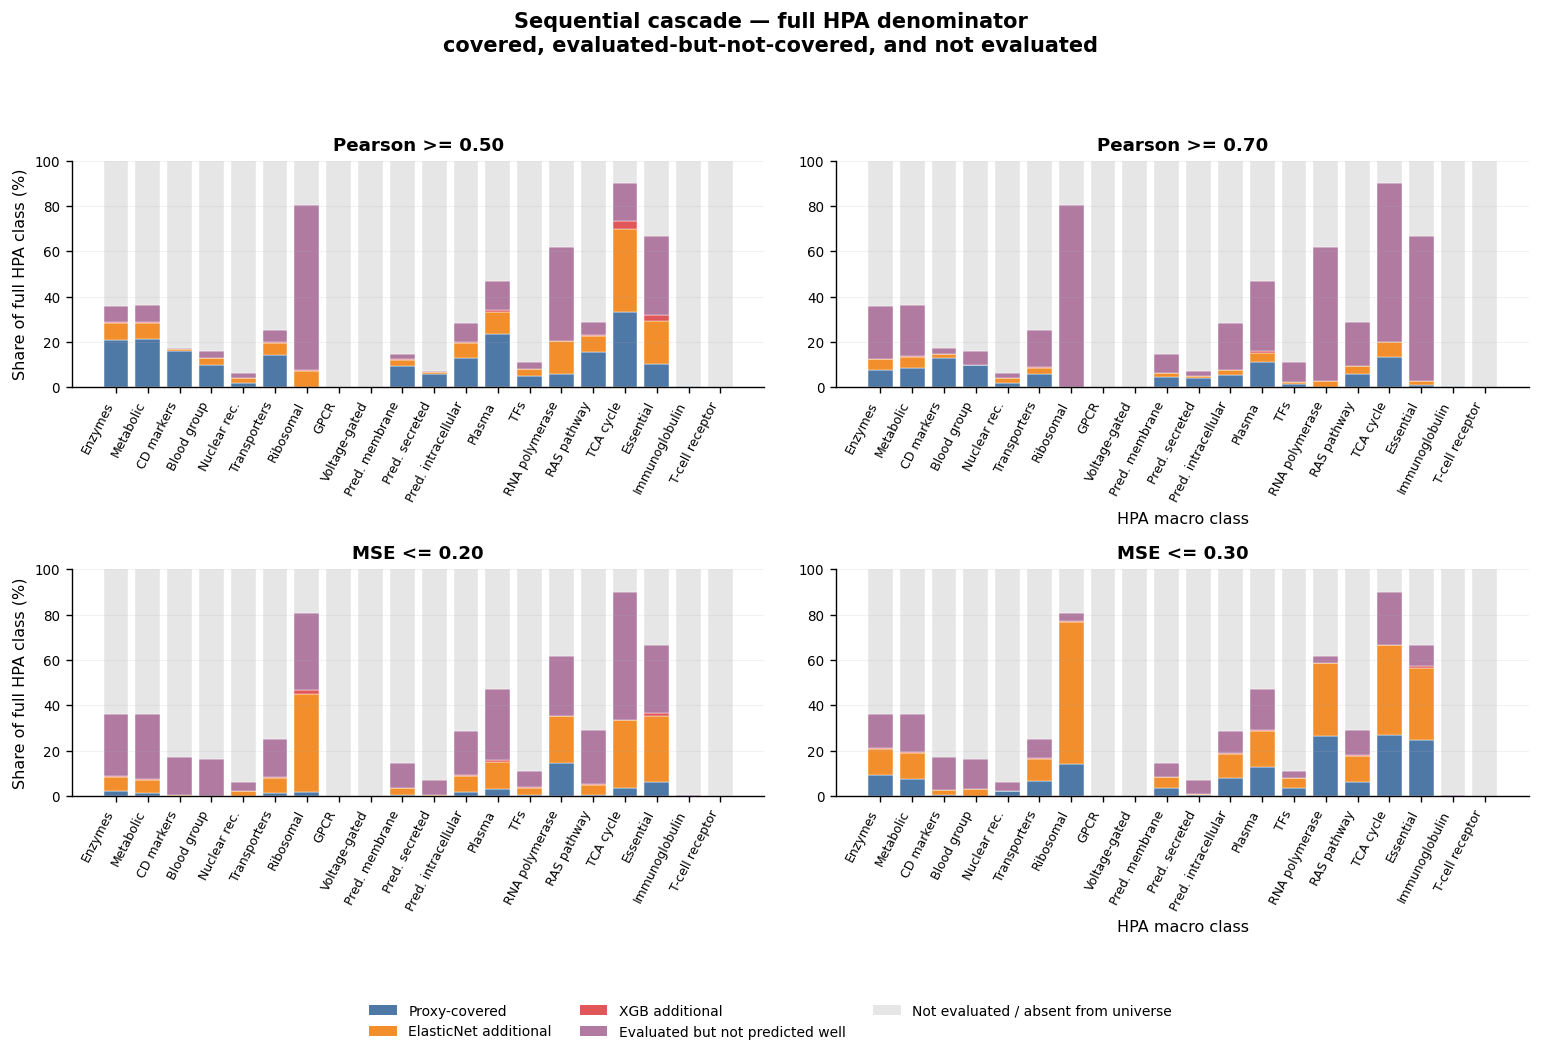

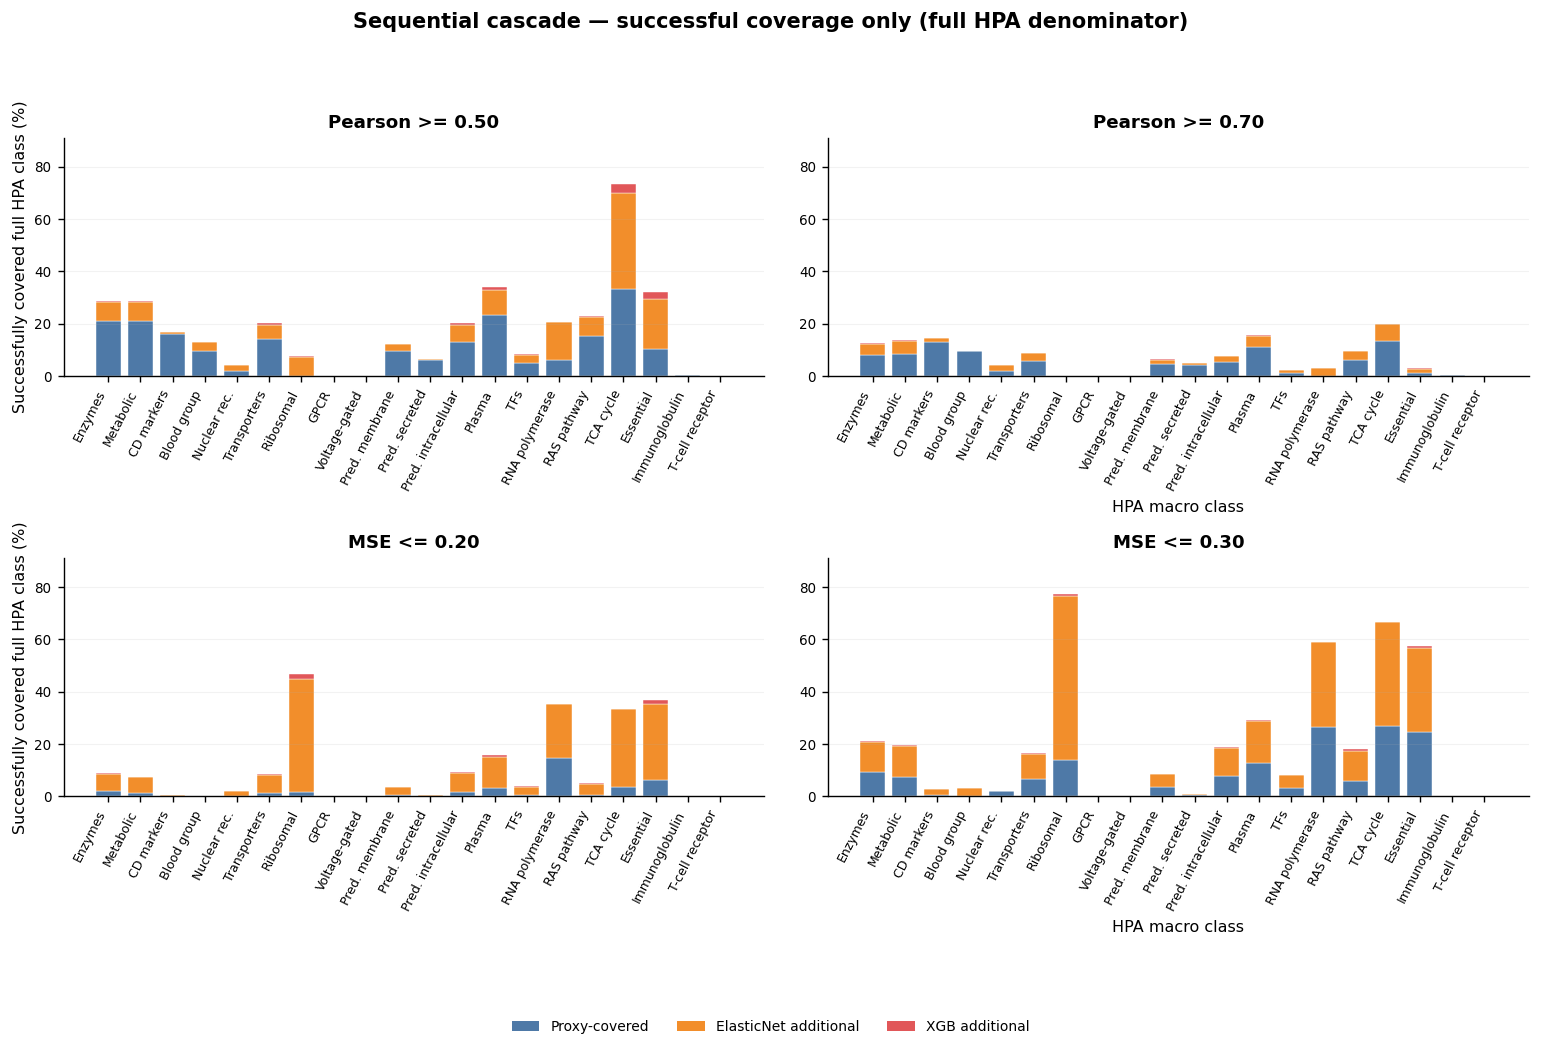

In [9]:
def _case_order_for_context(context_id):
    return case_table[case_table['context_id'].eq(context_id)].sort_values(
        ['metric_family', 'threshold_value'],
        key=lambda s: s.map(METRIC_ORDER) if s.name == 'metric_family' else s
    )


def _format_vertical_hpa_axis(ax):
    x = np.arange(len(HPA_MACRO_CLASSES))
    ax.set_xticks(x)
    ax.set_xticklabels(HPA_SHORT_LABELS, rotation=VERTICAL_LABEL_ROTATION, ha='right')
    ax.set_xlabel('HPA macro class')
    ax.grid(axis='y', alpha=0.16, linewidth=0.6)


def plot_full_decomposition_grid(data, context_id, stem_prefix):
    cases = _case_order_for_context(context_id)
    fig, axes, _, _ = compact_grid(len(cases), panel_size=VERTICAL_PANEL_SIZE, max_cols=2)
    for ax, case in zip(axes, cases.itertuples(index=False)):
        sub = data[data['case_id'].eq(case.case_id)]
        pivot = sub.pivot_table(
            index='hpa_macro_class', columns='component', values='pct_of_full_hpa_class',
            aggfunc='sum', fill_value=0, observed=False
        ).reindex(index=HPA_MACRO_CLASSES, columns=SEQUENTIAL_COMPONENTS, fill_value=0)
        x = np.arange(len(pivot))
        bottom = np.zeros(len(pivot))
        for component in SEQUENTIAL_COMPONENTS:
            values = pivot[component].to_numpy(dtype=float)
            ax.bar(
                x, values, bottom=bottom, width=BAR_WIDTH,
                color=FULL_DECOMPOSITION_COLORS[component],
                edgecolor='white', linewidth=0.25, label=component
            )
            bottom += values
        ax.set_ylim(0, 100)
        ax.set_ylabel('Share of full HPA class (%)')
        ax.set_title(case.case_label)
        _format_vertical_hpa_axis(ax)
    handles = [mpl.patches.Patch(facecolor=color, label=label) for label, color in FULL_DECOMPOSITION_COLORS.items()]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.005), ncol=3, frameon=False)
    fig.suptitle(
        'Sequential cascade — full HPA denominator\ncovered, evaluated-but-not-covered, and not evaluated',
        y=0.995, fontsize=12, fontweight='bold'
    )
    fig.tight_layout(rect=(0, 0.10, 1, 0.95), h_pad=1.2, w_pad=0.8)
    finish_figure(fig, f'{stem_prefix}_full_hpa_100pct_vertical_grid', show=DISPLAY_MAIN_FIGURES)


def plot_success_only_grid(data, context_id, stem_prefix):
    cases = _case_order_for_context(context_id)
    success_components = ['Proxy-covered', 'ElasticNet additional', 'XGB additional']
    max_value = 0.0
    pivots = {}
    for case in cases.itertuples(index=False):
        sub = data[data['case_id'].eq(case.case_id)]
        pivot = sub.pivot_table(
            index='hpa_macro_class', columns='component', values='pct_of_full_hpa_class',
            aggfunc='sum', fill_value=0, observed=False
        ).reindex(index=HPA_MACRO_CLASSES, columns=success_components, fill_value=0)
        pivots[case.case_id] = pivot
        max_value = max(max_value, float(pivot.sum(axis=1).max()))
    y_max = min(100, max(1.0, max_value * 1.18))

    fig, axes, _, _ = compact_grid(len(cases), panel_size=VERTICAL_PANEL_SIZE, max_cols=2)
    for ax, case in zip(axes, cases.itertuples(index=False)):
        pivot = pivots[case.case_id]
        x = np.arange(len(pivot))
        bottom = np.zeros(len(pivot))
        for component in success_components:
            values = pivot[component].to_numpy(dtype=float)
            ax.bar(
                x, values, bottom=bottom, width=BAR_WIDTH,
                color=FULL_DECOMPOSITION_COLORS[component],
                edgecolor='white', linewidth=0.25, label=component
            )
            bottom += values
        ax.set_ylim(0, y_max)
        ax.set_ylabel('Successfully covered full HPA class (%)')
        ax.set_title(case.case_label)
        _format_vertical_hpa_axis(ax)
    handles = [mpl.patches.Patch(facecolor=FULL_DECOMPOSITION_COLORS[c], label=c) for c in success_components]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=3, frameon=False)
    fig.suptitle('Sequential cascade — successful coverage only (full HPA denominator)', y=0.995, fontsize=12, fontweight='bold')
    fig.tight_layout(rect=(0, 0.10, 1, 0.95), h_pad=1.2, w_pad=0.8)
    finish_figure(fig, f'{stem_prefix}_successful_coverage_percentage_vertical_grid', show=DISPLAY_MAIN_FIGURES)


part1_figures = []
for context_id in case_table['context_id'].drop_duplicates():
    stem = safe_filename(f'part1_{context_id}')
    plot_full_decomposition_grid(sequential_full_hpa, context_id, stem)
    plot_success_only_grid(sequential_full_hpa, context_id, stem)
    part1_figures.extend([
        f'{stem}_full_hpa_100pct_vertical_grid',
        f'{stem}_successful_coverage_percentage_vertical_grid',
    ])

## Pearson–MSE overlap on a common evaluated universe

,context_id,metric_family,loose_threshold,strict_threshold,n_loose_good,n_strict_good,n_strict_only_violations,nested_as_expected
0,proxy_z__CCLE,Pearson,0.5,0.7,3668,1443,0,True
1,proxy_z__CCLE,MSE,0.3,0.2,3297,1625,0,True


,context_id,pearson_threshold,mse_threshold,n_common_evaluated_universe,n_pearson_good,n_mse_good,n_shared,n_union,jaccard,expected_shared_if_random,probability_zero_if_random_fixed_sizes,diagnosis
0,proxy_z__CCLE,0.5,0.2,5113,3668,1625,944,4349,0.217061,1165.753960,0.000000e+00,The selected sets overlap; use Jaccard and class composition to quantify disagreement.
1,proxy_z__CCLE,0.5,0.3,5113,3668,3297,2108,4857,0.434013,2365.225112,0.000000e+00,The selected sets overlap; use Jaccard and class composition to quantify disagreement.
2,proxy_z__CCLE,0.7,0.2,5113,1443,1625,173,2895,0.059758,458.610405,1.116825e-294,The selected sets overlap; use Jaccard and class composition to quantify disagreement.
3,proxy_z__CCLE,0.7,0.3,5113,1443,3297,525,4215,0.124555,930.485234,0.000000e+00,The selected sets overlap; use Jaccard and class composition to quantify disagreement.


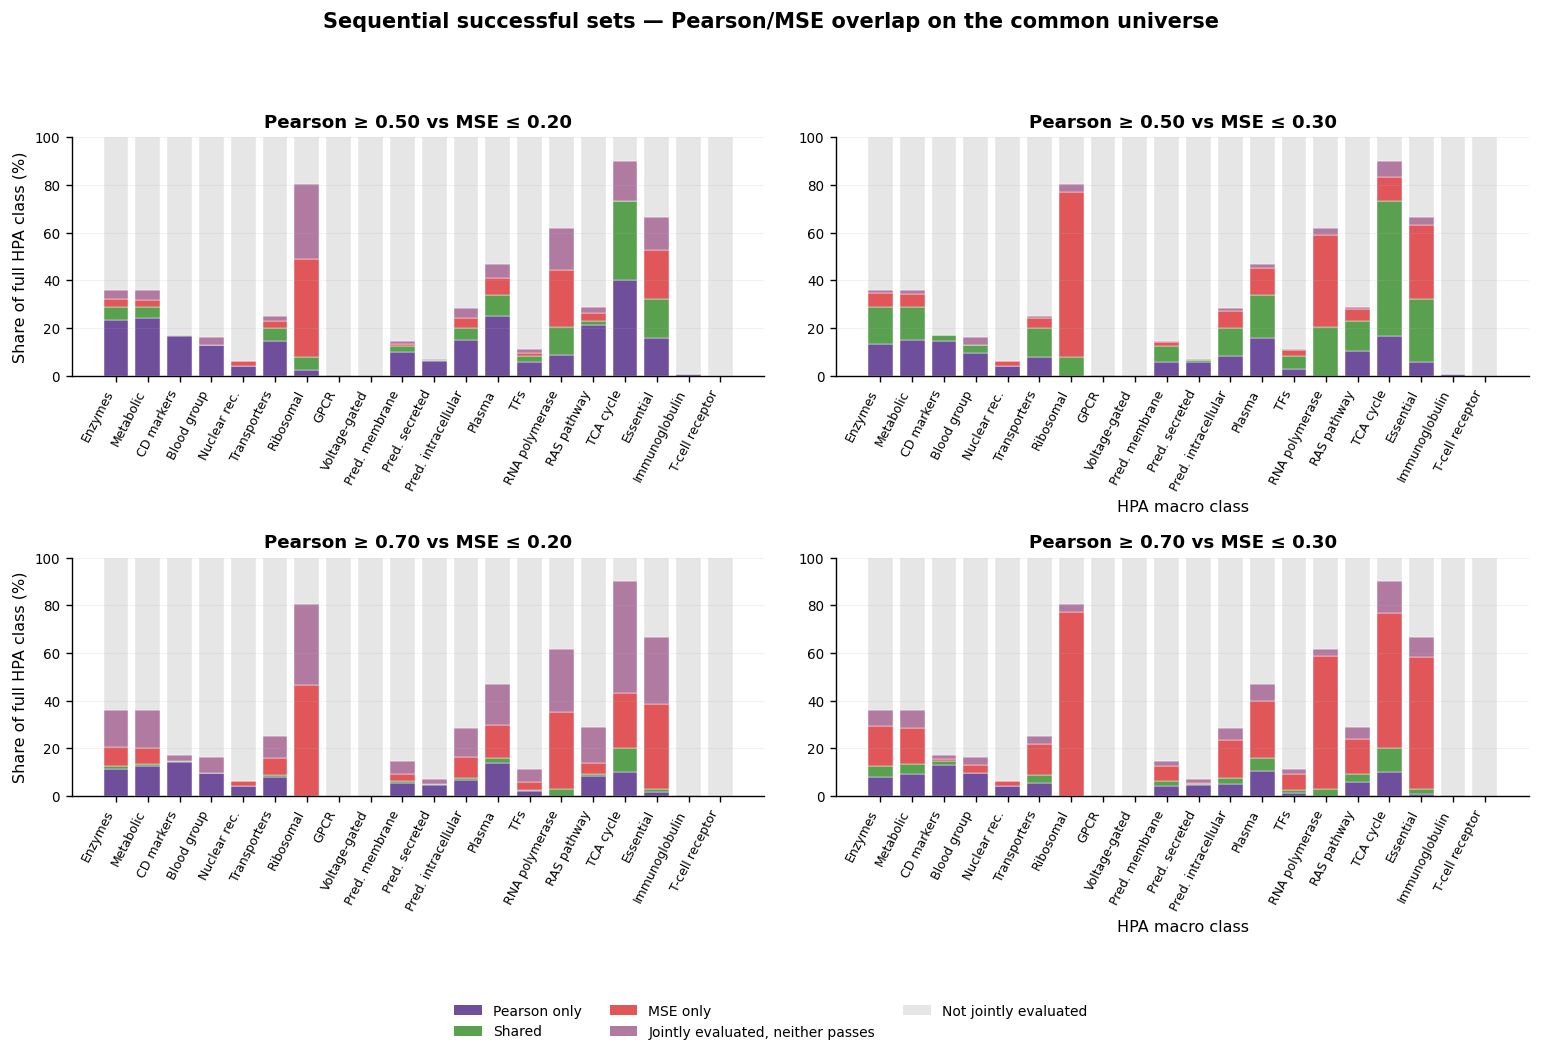

In [10]:
def find_case_id(case_df, context_id, metric, threshold):
    hit = case_df[
        case_df['context_id'].eq(context_id)
        & case_df['metric_family'].eq(metric)
        & np.isclose(case_df['threshold_value'].astype(float), threshold)
    ]
    return None if hit.empty else hit.iloc[0]['case_id']


success_by_case = {
    case_id: set(group.loc[group['stage_group'].isin(SUCCESS_STAGES), 'gene_symbol'])
    for case_id, group in selected.groupby('case_id')
}
universe_by_case = {
    case_id: set(group['gene_symbol'])
    for case_id, group in selected.groupby('case_id')
}

# Expected threshold nesting.
nesting_rows = []
for context_id in case_table['context_id'].drop_duplicates():
    for metric, loose, strict in [('Pearson', 0.50, 0.70), ('MSE', 0.30, 0.20)]:
        loose_id = find_case_id(case_table, context_id, metric, loose)
        strict_id = find_case_id(case_table, context_id, metric, strict)
        if loose_id is None or strict_id is None:
            continue
        loose_set = success_by_case.get(loose_id, set())
        strict_set = success_by_case.get(strict_id, set())
        violations = strict_set - loose_set
        nesting_rows.append((context_id, metric, loose, strict, len(loose_set), len(strict_set), len(violations), len(violations) == 0))
sequential_nesting_audit = pd.DataFrame(
    nesting_rows,
    columns=['context_id', 'metric_family', 'loose_threshold', 'strict_threshold', 'n_loose_good', 'n_strict_good',
             'n_strict_only_violations', 'nested_as_expected']
)
sequential_nesting_audit.to_csv(TABLE_DIR / 'part1_threshold_nesting_audit.csv', index=False)
display(sequential_nesting_audit)

# Pairwise Pearson/MSE overlap, always restricted to the intersection of evaluated universes.
audit_rows = []
overlap_rows = []
for context_id in case_table['context_id'].drop_duplicates():
    for p_thr in PEARSON_THRESHOLDS:
        for m_thr in MSE_THRESHOLDS:
            p_id = find_case_id(case_table, context_id, 'Pearson', p_thr)
            m_id = find_case_id(case_table, context_id, 'MSE', m_thr)
            if p_id is None or m_id is None:
                continue
            common = universe_by_case[p_id] & universe_by_case[m_id]
            p_good = success_by_case[p_id] & common
            m_good = success_by_case[m_id] & common
            shared = p_good & m_good
            union = p_good | m_good
            n = len(common)
            expected = len(p_good) * len(m_good) / n if n else np.nan
            p_zero = probability_zero_overlap(n, len(p_good), len(m_good))
            audit_rows.append((
                context_id, p_thr, m_thr, n, len(p_good), len(m_good), len(shared), len(union),
                len(shared) / len(union) if union else 0.0, expected, p_zero,
                zero_overlap_diagnosis(n, len(p_good), len(m_good), len(shared), p_zero)
            ))

            for hpa_class in HPA_MACRO_CLASSES:
                class_genes = set(hpa_macro.loc[hpa_macro['hpa_macro_class'].eq(hpa_class), 'gene_symbol'])
                c_common = class_genes & common
                categories = {
                    'Pearson only': len((p_good - m_good) & class_genes),
                    'Shared': len(shared & class_genes),
                    'MSE only': len((m_good - p_good) & class_genes),
                    'Jointly evaluated, neither passes': len(c_common - union),
                    'Not jointly evaluated': HPA_REFERENCE_COUNTS[hpa_class] - len(c_common),
                }
                if categories['Not jointly evaluated'] < 0:
                    raise ValueError(f'Common-universe HPA count exceeds reference denominator for {hpa_class}.')
                for component, count in categories.items():
                    overlap_rows.append((context_id, p_thr, m_thr, hpa_class, component, count, 100.0 * count / HPA_REFERENCE_COUNTS[hpa_class]))

sequential_zero_overlap_audit = pd.DataFrame(
    audit_rows,
    columns=['context_id', 'pearson_threshold', 'mse_threshold', 'n_common_evaluated_universe',
             'n_pearson_good', 'n_mse_good', 'n_shared', 'n_union', 'jaccard',
             'expected_shared_if_random', 'probability_zero_if_random_fixed_sizes', 'diagnosis']
)
sequential_zero_overlap_audit.to_csv(TABLE_DIR / 'part1_pearson_mse_common_universe_overlap_audit.csv', index=False)
display(sequential_zero_overlap_audit)

sequential_pearson_mse_hpa = pd.DataFrame(
    overlap_rows,
    columns=['context_id', 'pearson_threshold', 'mse_threshold', 'hpa_macro_class', 'component', 'n_genes', 'pct_of_full_hpa_class']
)
sequential_pearson_mse_hpa.to_csv(TABLE_DIR / 'part1_pearson_mse_hpa_full_denominator_overlap.csv', index=False)

for context_id in case_table['context_id'].drop_duplicates():
    pairs = [(p, m) for p in PEARSON_THRESHOLDS for m in MSE_THRESHOLDS]
    fig, axes, _, _ = compact_grid(len(pairs), panel_size=VERTICAL_PANEL_SIZE, max_cols=2)
    for ax, (p_thr, m_thr) in zip(axes, pairs):
        sub = sequential_pearson_mse_hpa[
            sequential_pearson_mse_hpa['context_id'].eq(context_id)
            & np.isclose(sequential_pearson_mse_hpa['pearson_threshold'], p_thr)
            & np.isclose(sequential_pearson_mse_hpa['mse_threshold'], m_thr)
        ]
        pivot = sub.pivot_table(
            index='hpa_macro_class', columns='component', values='pct_of_full_hpa_class',
            aggfunc='sum', fill_value=0
        ).reindex(index=HPA_MACRO_CLASSES, columns=list(PEARSON_MSE_COLORS), fill_value=0)
        x = np.arange(len(pivot))
        bottom = np.zeros(len(pivot))
        for component, color in PEARSON_MSE_COLORS.items():
            vals = pivot[component].to_numpy(dtype=float)
            ax.bar(x, vals, bottom=bottom, width=BAR_WIDTH, color=color, edgecolor='white', linewidth=0.25)
            bottom += vals
        ax.set_ylim(0, 100)
        ax.set_ylabel('Share of full HPA class (%)')
        ax.set_title(f'Pearson ≥ {p_thr:.2f} vs MSE ≤ {m_thr:.2f}')
        _format_vertical_hpa_axis(ax)
    handles = [mpl.patches.Patch(facecolor=color, label=label) for label, color in PEARSON_MSE_COLORS.items()]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.005), ncol=3, frameon=False)
    fig.suptitle('Sequential successful sets — Pearson/MSE overlap on the common universe', y=0.995, fontsize=12, fontweight='bold')
    fig.tight_layout(rect=(0, 0.10, 1, 0.95), h_pad=1.2, w_pad=0.8)
    finish_figure(fig, f'part1_{safe_filename(context_id)}_pearson_mse_overlap_percentage_vertical_grid', show=DISPLAY_MAIN_FIGURES)
    part1_figures.append(f'part1_{safe_filename(context_id)}_pearson_mse_overlap_percentage_vertical_grid')

# Part 2 — Standalone model scores, using the full HPA denominator

In [11]:
GENE_COLUMN_CANDIDATES = [
    'gene_symbol', 'gene', 'Gene', 'protein', 'protein_name', 'target', 'feature', 'Unnamed: 0'
]
MODEL_COLUMN_CANDIDATES = ['model', 'model_name', 'estimator', 'method', 'algorithm']
METRIC_COLUMN_CANDIDATES = ['metric', 'metric_family', 'measure', 'score_name']
VALUE_COLUMN_CANDIDATES = ['value', 'score', 'metric_value', 'performance', 'result']


def metric_from_column_name(column):
    text = normalize_text(column)
    if 'threshold' in text or 'cutoff' in text:
        return None
    return parse_metric_family(text)


def model_from_column_name(column):
    return canonical_model(column)


def infer_gene_column(df):
    col = pick_column(df, GENE_COLUMN_CANDIDATES, required=False)
    if col is not None:
        return col
    # Conservative fallback: first mostly non-numeric column with many unique values.
    for candidate in list(df.columns)[:5]:
        series = df[candidate]
        numeric_fraction = pd.to_numeric(series, errors='coerce').notna().mean()
        if numeric_fraction < 0.25 and series.nunique(dropna=True) > 10:
            return candidate
    return None


def standardize_score_frame(df, source_path):
    source_path = str(source_path)
    if df is None or df.empty:
        return pd.DataFrame(columns=['gene_symbol', 'model', 'metric_family', 'score', 'source_file'])
    gene_col = infer_gene_column(df)
    if gene_col is None:
        return pd.DataFrame(columns=['gene_symbol', 'model', 'metric_family', 'score', 'source_file'])

    model_col = pick_column(df, MODEL_COLUMN_CANDIDATES, required=False)
    metric_col = pick_column(df, METRIC_COLUMN_CANDIDATES, required=False)
    value_col = pick_column(df, VALUE_COLUMN_CANDIDATES, required=False)
    file_model = canonical_model(source_path)
    rows = []

    # Long layout.
    if metric_col is not None and value_col is not None:
        temp = pd.DataFrame({
            'gene_symbol': df[gene_col].map(clean_gene_symbol),
            'metric_family': df[metric_col].map(parse_metric_family),
            'score': pd.to_numeric(df[value_col], errors='coerce'),
        })
        if model_col is not None:
            temp['model'] = df[model_col].map(canonical_model)
        else:
            temp['model'] = file_model
        rows.append(temp)

    # Semi-wide layout with an explicit model column, or one file per model.
    explicit_or_file_model = model_col is not None or file_model is not None
    if explicit_or_file_model:
        for col in df.columns:
            metric = metric_from_column_name(col)
            if metric is None:
                continue
            # In semi-wide mode, do not use columns that encode a different model.
            encoded_model = model_from_column_name(col)
            if model_col is not None and encoded_model is not None:
                continue
            temp = pd.DataFrame({
                'gene_symbol': df[gene_col].map(clean_gene_symbol),
                'model': df[model_col].map(canonical_model) if model_col is not None else file_model,
                'metric_family': metric,
                'score': pd.to_numeric(df[col], errors='coerce'),
            })
            rows.append(temp)

    # Fully wide layout: model and metric both encoded in each column name.
    for col in df.columns:
        metric = metric_from_column_name(col)
        model = model_from_column_name(col)
        if metric is None or model is None:
            continue
        temp = pd.DataFrame({
            'gene_symbol': df[gene_col].map(clean_gene_symbol),
            'model': model,
            'metric_family': metric,
            'score': pd.to_numeric(df[col], errors='coerce'),
        })
        rows.append(temp)

    if not rows:
        return pd.DataFrame(columns=['gene_symbol', 'model', 'metric_family', 'score', 'source_file'])
    out = pd.concat(rows, ignore_index=True)
    out['source_file'] = source_path
    out = out.dropna(subset=['gene_symbol', 'model', 'metric_family', 'score'])
    out = out[out['model'].isin(MODELS) & out['metric_family'].isin(SELECTED_THRESHOLDS_BY_METRIC)]
    return out.drop_duplicates()


def discover_independent_score_files():
    manual = [Path(p) for p in INDEPENDENT_SCORE_FILES if Path(p).exists()]
    if manual:
        return manual
    if not AUTO_SEARCH_INDEPENDENT_SCORE_FILES:
        return []
    allowed_suffixes = {'.csv', '.tsv', '.txt', '.parquet', '.gz', '.zip'}
    name_tokens = ('proxy', 'elastic', 'enet', 'xgb', 'xgboost', 'model', 'prediction', 'metric', 'score', 'performance', 'evaluation')
    excluded_tokens = (
        '4.0_hpa_outputs', '4.0_hpa_v3_outputs', '4.0_hpa_v4_outputs', 'hpa_macroclass_', 'protein_names_by_cascade_partition',
        'proteinatlas', 'selected_standardized_cascade_partitions'
    )
    candidates = []
    for p in BASE_DIR.rglob('*'):
        if not p.is_file() or p.suffix.lower() not in allowed_suffixes:
            continue
        text = str(p).casefold()
        if any(token in text for token in excluded_tokens):
            continue
        if any(token in text for token in name_tokens):
            candidates.append(p)
    candidates = sorted(set(candidates), key=lambda p: (len(p.parts), str(p)))
    return candidates[:MAX_AUTO_SCORE_FILES]


score_files = discover_independent_score_files()
standardized_frames = []
read_failures = []
for path in score_files:
    try:
        frame = read_table_any(path)
        standardized = standardize_score_frame(frame, path)
        if not standardized.empty:
            standardized_frames.append(standardized)
    except Exception as exc:
        read_failures.append((str(path), str(exc)))

# Also inspect the cascade export for genuine wide score columns. This does not
# use the stage assignments; it only accepts columns that explicitly encode a model+metric.
cascade_wide_scores = standardize_score_frame(raw_partitions, 'cascade_export_wide_score_columns')
if not cascade_wide_scores.empty:
    standardized_frames.append(cascade_wide_scores)

if standardized_frames:
    independent_scores_raw = pd.concat(standardized_frames, ignore_index=True)
    duplicate_profile = (
        independent_scores_raw.groupby(['gene_symbol', 'model', 'metric_family'])['score']
        .agg(n_values='size', min_score='min', max_score='max')
        .reset_index()
    )
    duplicates = duplicate_profile[duplicate_profile['n_values'] > 1]
    if len(duplicates):
        print(f'Duplicate score groups: {len(duplicates):,}; reducing with {DUPLICATE_SCORE_AGGREGATION}.')
    agg_func = {'median': 'median', 'mean': 'mean', 'min': 'min', 'max': 'max'}[DUPLICATE_SCORE_AGGREGATION]
    independent_scores = (
        independent_scores_raw.groupby(['gene_symbol', 'model', 'metric_family'], as_index=False)['score']
        .agg(agg_func)
    )
    independent_scores.to_csv(TABLE_DIR / 'part2_independent_scores_standardized.csv', index=False)
    duplicate_profile.to_csv(TABLE_DIR / 'part2_independent_score_duplicate_profile.csv', index=False)
    INDEPENDENT_AVAILABLE = True
else:
    independent_scores_raw = pd.DataFrame(columns=['gene_symbol', 'model', 'metric_family', 'score', 'source_file'])
    independent_scores = independent_scores_raw.copy()
    INDEPENDENT_AVAILABLE = False

print(f'Candidate score files inspected: {len(score_files)}')
for path in score_files[:20]:
    print(' -', path)
if len(score_files) > 20:
    print(f' ... plus {len(score_files)-20} more')
if read_failures:
    print(f'Files that could not be read: {len(read_failures)} (saved to a table)')
    pd.DataFrame(read_failures, columns=['source_file', 'error']).to_csv(TABLE_DIR / 'part2_score_file_read_failures.csv', index=False)

if INDEPENDENT_AVAILABLE:
    score_inventory = (
        independent_scores.groupby(['model', 'metric_family'])['gene_symbol']
        .nunique().unstack(fill_value=0).reindex(index=MODELS, columns=list(SELECTED_THRESHOLDS_BY_METRIC), fill_value=0)
    )
    print(f'Standardized independent score rows: {len(independent_scores):,}')
    display(score_inventory)
else:
    message = (
        '**Standalone score tables were not found.** Part 1 is complete, but Part 2 cannot be reconstructed from the cascade stage column. '
        'Set `INDEPENDENT_SCORE_FILES` to one or more per-protein score tables and rerun from this cell.'
    )
    display(Markdown(message))
    if REQUIRE_INDEPENDENT_SCORES:
        raise FileNotFoundError(message)

Duplicate score groups: 30,702; reducing with median.
Candidate score files inspected: 65
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_outputs\atlas_performance_standardized.csv
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_outputs\atlas_three_way_metric_overlap_statistics.csv
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\atlas_outputs\best_metric_scores_wide.csv
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\comparison_outputs\all_model_results_summary.csv
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\comparison_outputs\model_counts_by_run.csv
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\model_performance_test_plots\all_results_with_proxy_test_metrics.csv
 - c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\model_performance_test_plots\elasticnet_metric_wise_best_te

metric_family,Pearson,MSE
model,,
Proxy model,5142,5140
ElasticNet,5136,5139
XGB,5132,5135


## Standalone-score universe and percentage analyses

This section is executed only when genuine per-protein scores are available. Cascade stage labels are never treated as standalone model scores.

### Full HPA sets versus the standalone-score universe

,n_hpa_genes,n_hpa_genes_in_loaded_file,"('Pearson >= 0.50', 'intersection n')","('Pearson >= 0.50', 'intersection %')","('Pearson >= 0.50', 'not in universe n')","('Pearson >= 0.70', 'intersection n')","('Pearson >= 0.70', 'intersection %')","('Pearson >= 0.70', 'not in universe n')","('MSE <= 0.20', 'intersection n')","('MSE <= 0.20', 'intersection %')","('MSE <= 0.20', 'not in universe n')","('MSE <= 0.30', 'intersection n')","('MSE <= 0.30', 'intersection %')","('MSE <= 0.30', 'not in universe n')"
hpa_macro_class,,,,,,,,,,,,,,
Enzymes,3777,3777,1360,36.01%,2417,1360,36.01%,2417,1360,36.01%,2417,1360,36.01%,2417
Metabolic proteins,2882,2882,1040,36.09%,1842,1040,36.09%,1842,1040,36.09%,1842,1040,36.09%,1842
CD markers,384,384,66,17.19%,318,66,17.19%,318,66,17.19%,318,66,17.19%,318
Blood group antigen proteins,31,31,5,16.13%,26,5,16.13%,26,5,16.13%,26,5,16.13%,26
Nuclear receptors,49,49,3,6.12%,46,3,6.12%,46,3,6.12%,46,3,6.12%,46
Transporters,2137,2137,535,25.04%,1602,535,25.04%,1602,535,25.04%,1602,535,25.04%,1602
Ribosomal proteins,180,180,145,80.56%,35,145,80.56%,35,145,80.56%,35,145,80.56%,35
G-protein coupled receptors,743,743,1,0.13%,742,1,0.13%,742,1,0.13%,742,1,0.13%,742
Voltage-gated ion channels,132,132,0,0.00%,132,0,0.00%,132,0,0.00%,132,0,0.00%,132


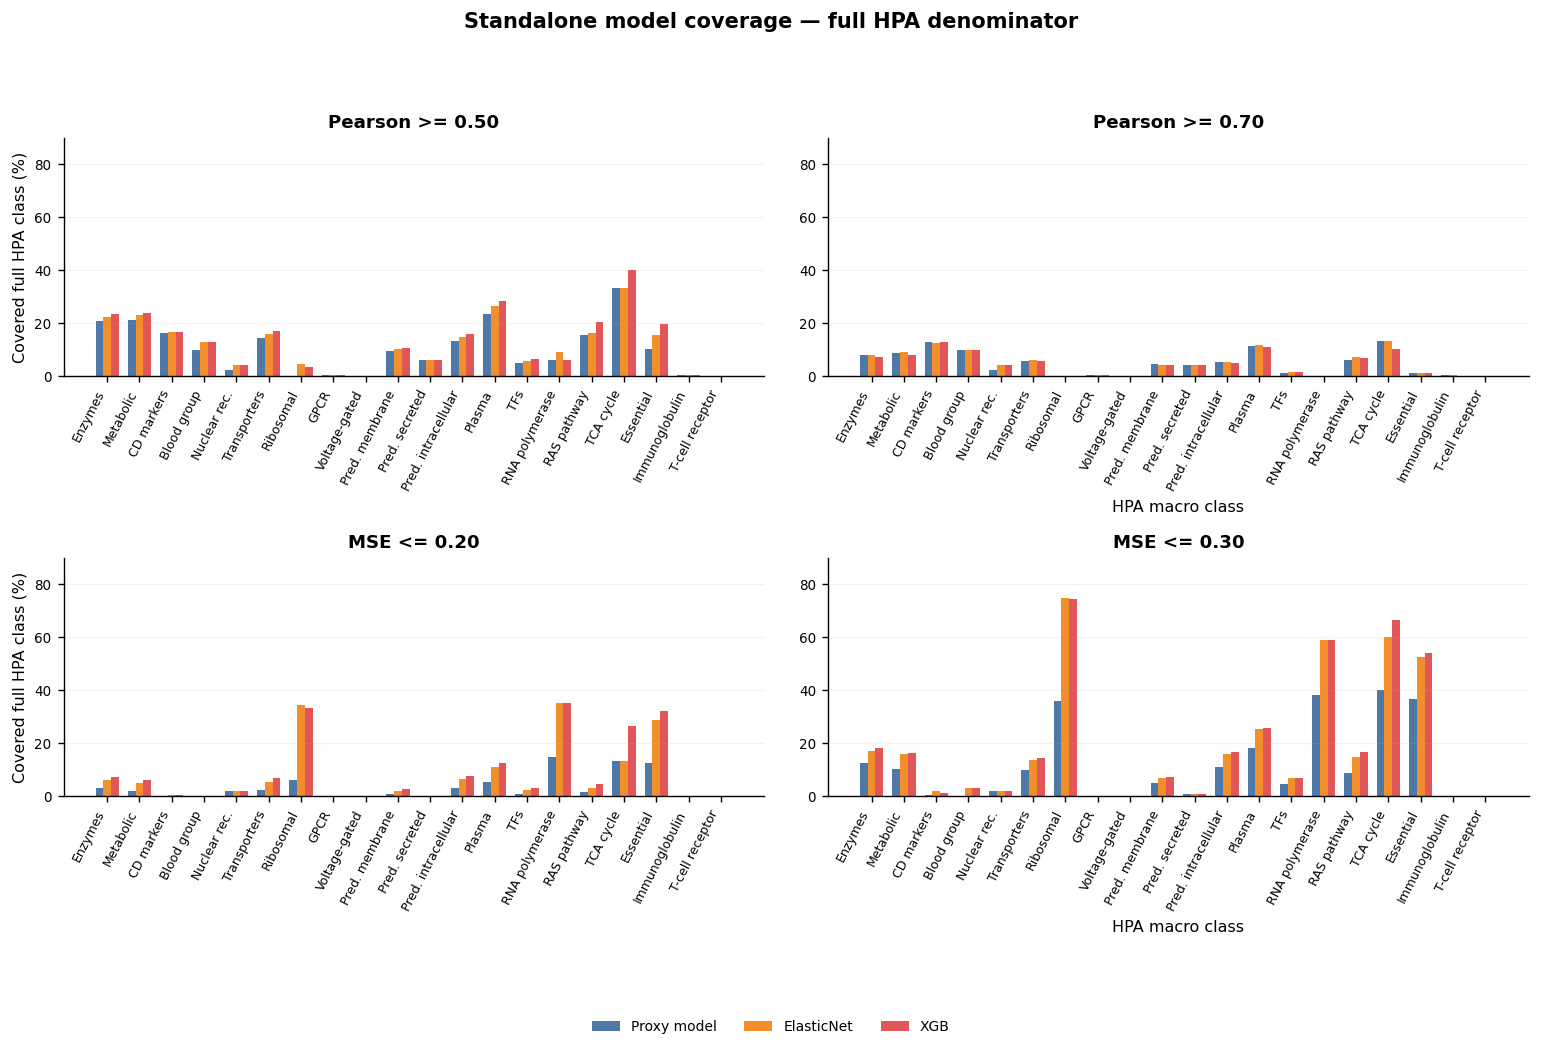

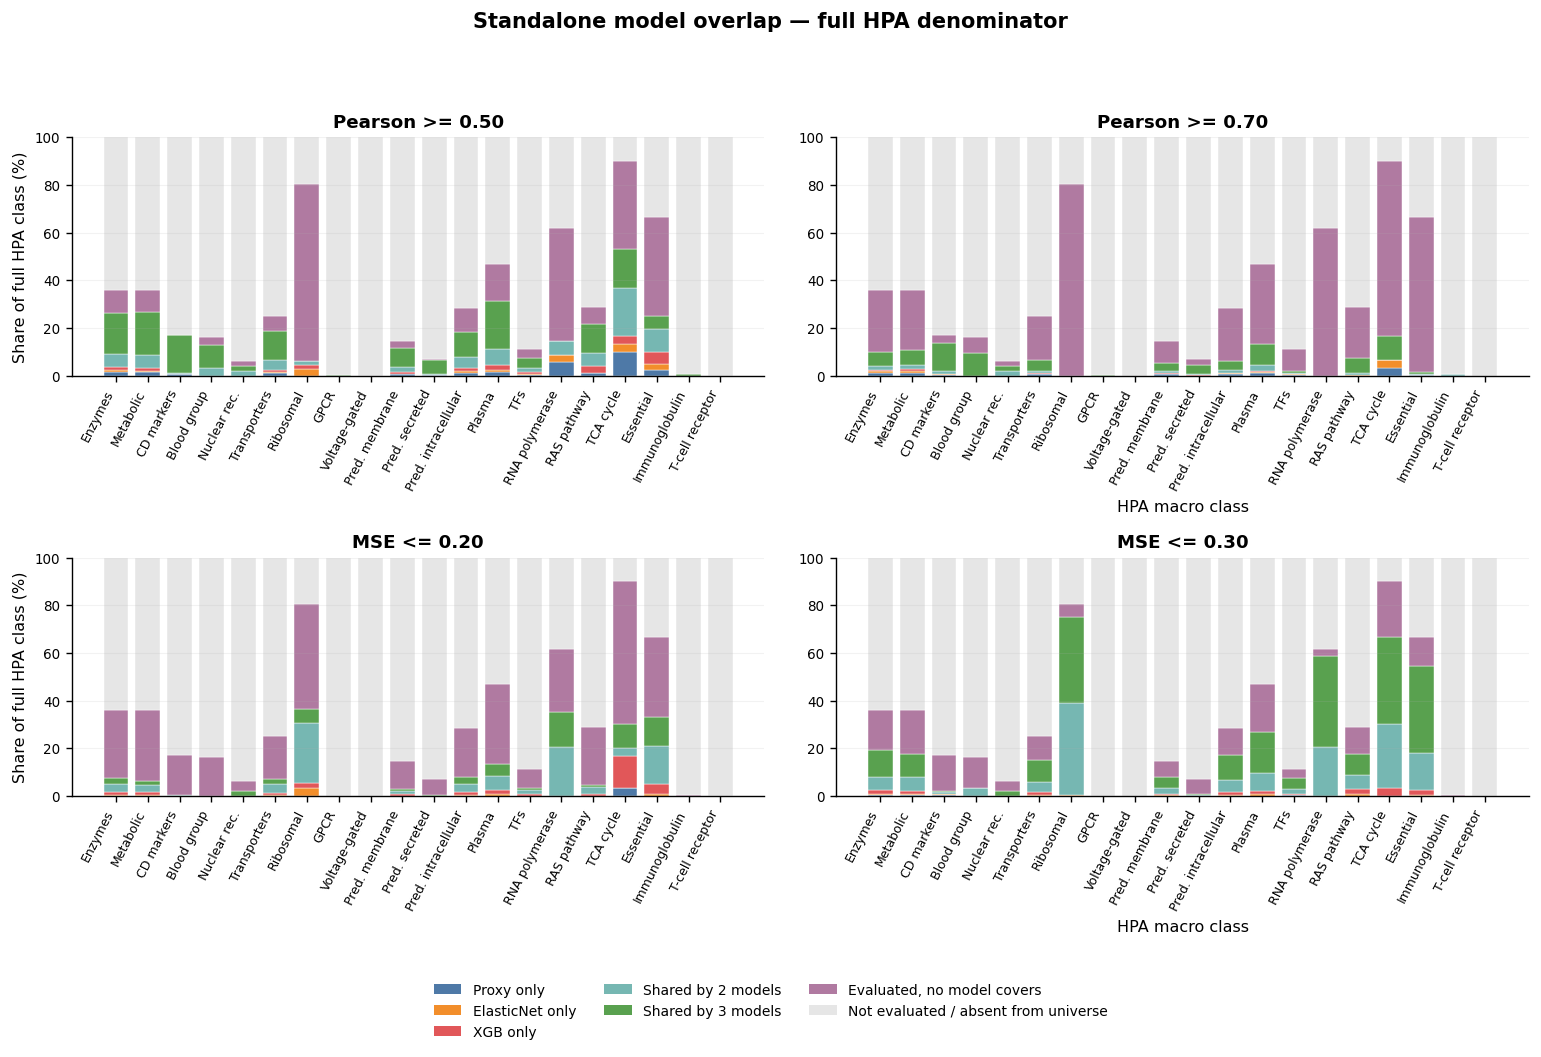

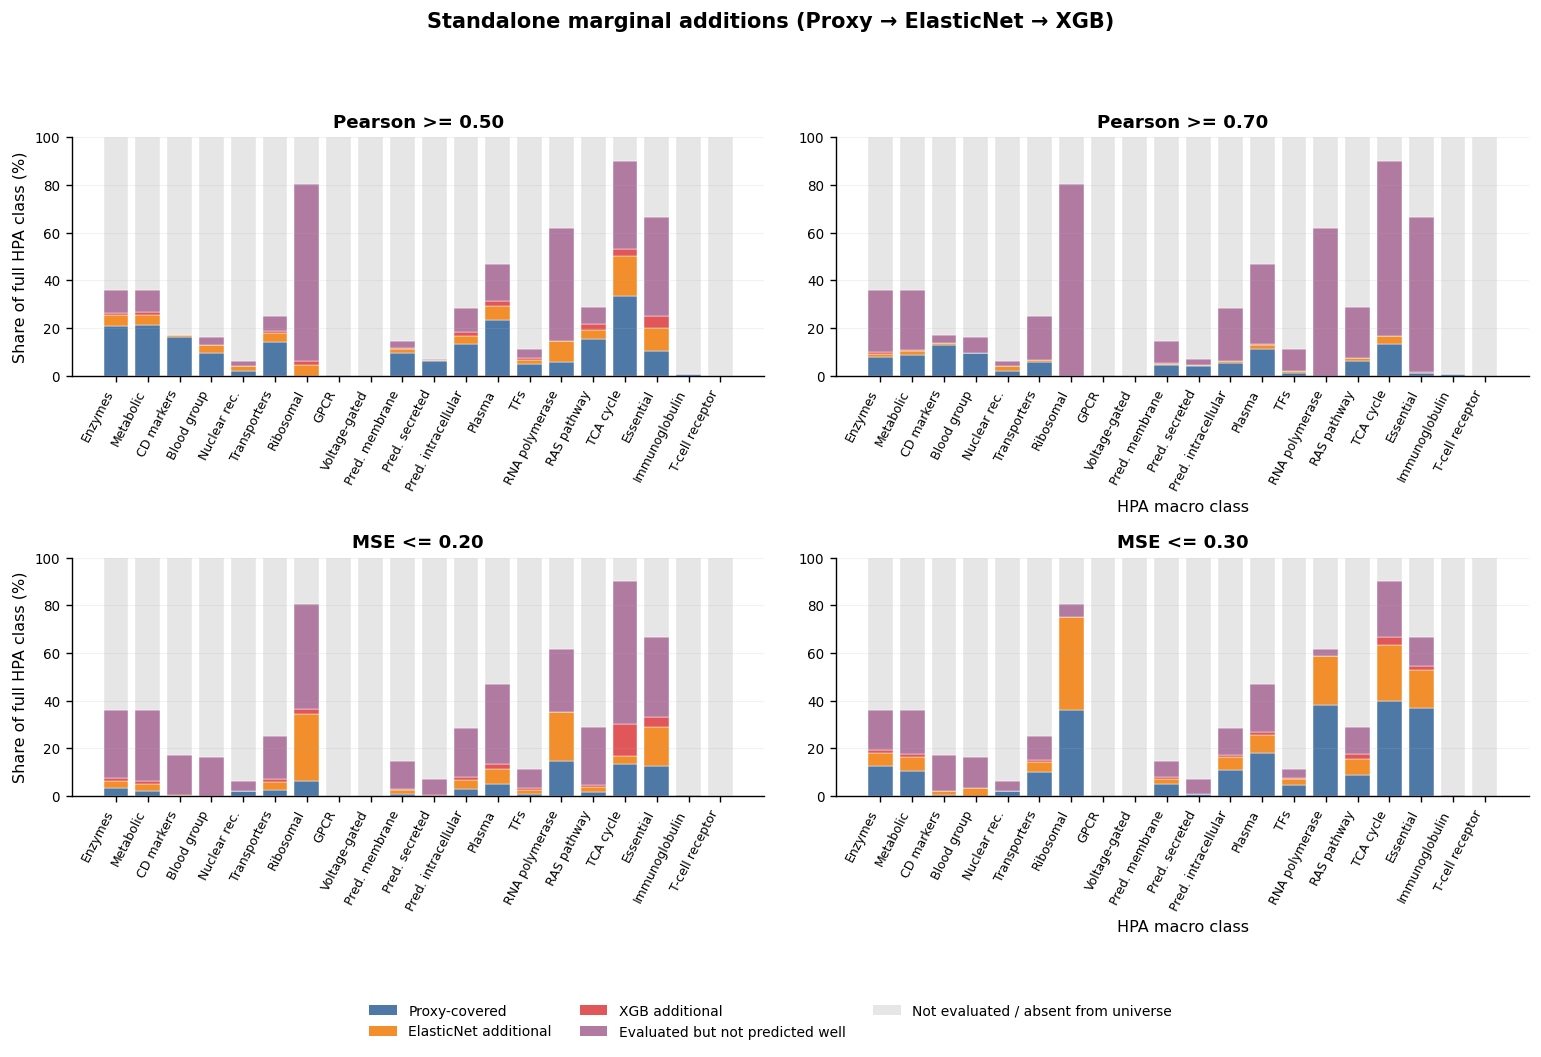

In [12]:
part2_figures = []

if INDEPENDENT_AVAILABLE:
    independent_cases = pd.DataFrame([
        {
            'metric_family': metric,
            'threshold_value': float(threshold),
            'case_id': safe_filename(f'{metric}__{threshold:.2f}'),
            'case_label': threshold_label(metric, threshold),
        }
        for metric, thresholds in SELECTED_THRESHOLDS_BY_METRIC.items()
        for threshold in thresholds
    ])
    independent_cases['metric_order'] = independent_cases['metric_family'].map(METRIC_ORDER)
    independent_cases = independent_cases.sort_values(['metric_order', 'threshold_value']).drop(columns='metric_order')

    hit_rows, evaluated_rows = [], []
    for case in independent_cases.itertuples(index=False):
        metric_scores = independent_scores[independent_scores['metric_family'].eq(case.metric_family)]
        for model in MODELS:
            model_scores = metric_scores[metric_scores['model'].eq(model)]
            evaluated = set(model_scores['gene_symbol'])
            hits = set(model_scores.loc[
                passes_threshold(model_scores['score'], case.metric_family, case.threshold_value), 'gene_symbol'
            ])
            hit_rows.extend((case.case_id, case.case_label, case.metric_family, case.threshold_value, model, g) for g in hits)
            evaluated_rows.extend((case.case_id, case.metric_family, case.threshold_value, model, g) for g in evaluated)

    independent_hits = pd.DataFrame(
        hit_rows, columns=['case_id', 'case_label', 'metric_family', 'threshold_value', 'model', 'gene_symbol']
    ).drop_duplicates()
    independent_evaluated = pd.DataFrame(
        evaluated_rows, columns=['case_id', 'metric_family', 'threshold_value', 'model', 'gene_symbol']
    ).drop_duplicates()
    independent_hits.to_csv(TABLE_DIR / 'part2_independent_threshold_hits_long.csv', index=False)

    universe_rows = []
    for case in independent_cases.itertuples(index=False):
        model_sets = {
            model: set(independent_evaluated.loc[
                independent_evaluated['case_id'].eq(case.case_id) & independent_evaluated['model'].eq(model), 'gene_symbol'
            ]) for model in MODELS
        }
        if INDEPENDENT_UNIVERSE_MODE == 'intersection':
            universe = set.intersection(*(model_sets[m] for m in MODELS)) if all(model_sets[m] for m in MODELS) else set()
        else:
            universe = set.union(*(model_sets[m] for m in MODELS))
        universe_rows.extend((case.case_id, gene) for gene in universe)
    independent_universe = pd.DataFrame(universe_rows, columns=['case_id', 'gene_symbol']).drop_duplicates()

    # Full HPA versus standalone universe table.
    standalone_grid = (
        independent_cases.assign(_key=1)
        .merge(hpa_reference.assign(_key=1), on='_key').drop(columns='_key')
        .merge(hpa_loaded_counts, on='hpa_macro_class', how='left')
    )
    standalone_universe_counts = (
        independent_universe.merge(hpa_macro, on='gene_symbol', how='inner')
        .groupby(['case_id', 'hpa_macro_class'], observed=True)['gene_symbol']
        .nunique().reset_index(name='n_hpa_genes_in_standalone_universe')
    )
    standalone_universe_table = standalone_grid.merge(standalone_universe_counts, on=['case_id', 'hpa_macro_class'], how='left')
    standalone_universe_table['n_hpa_genes_in_standalone_universe'] = standalone_universe_table['n_hpa_genes_in_standalone_universe'].fillna(0).astype(int)
    standalone_universe_table['pct_full_hpa_in_standalone_universe'] = safe_percent(
        standalone_universe_table['n_hpa_genes_in_standalone_universe'], standalone_universe_table['n_hpa_genes']
    )
    standalone_universe_table['n_hpa_genes_not_in_standalone_universe'] = (
        standalone_universe_table['n_hpa_genes'] - standalone_universe_table['n_hpa_genes_in_standalone_universe']
    )
    if (standalone_universe_table['n_hpa_genes_not_in_standalone_universe'] < 0).any():
        raise ValueError('Standalone universe exceeds a supplied HPA class denominator.')
    standalone_universe_table.to_csv(TABLE_DIR / 'part2_full_hpa_vs_standalone_universe.csv', index=False)

    standalone_wide = hpa_reference.merge(hpa_loaded_counts, on='hpa_macro_class', how='left').set_index('hpa_macro_class')
    pieces = [standalone_wide]
    for case in independent_cases.itertuples(index=False):
        one = standalone_universe_table[standalone_universe_table['case_id'].eq(case.case_id)].set_index('hpa_macro_class')
        part = one[['n_hpa_genes_in_standalone_universe', 'pct_full_hpa_in_standalone_universe', 'n_hpa_genes_not_in_standalone_universe']].copy()
        part.columns = pd.MultiIndex.from_product([[case.case_label], ['intersection n', 'intersection %', 'not in universe n']])
        pieces.append(part)
    display(Markdown('### Full HPA sets versus the standalone-score universe'))
    display(pd.concat(pieces, axis=1).reindex(HPA_MACRO_CLASSES).style.format(
        {c: '{:.2f}%' for c in pd.concat(pieces, axis=1).columns if isinstance(c, tuple) and c[1] == 'intersection %'},
        na_rep='0'
    ))

    # Per-model standalone coverage as a percentage of the full HPA class.
    coverage_grid = (
        independent_cases.assign(_key=1)
        .merge(hpa_reference.assign(_key=1), on='_key')
        .merge(pd.DataFrame({'model': MODELS, '_key': 1}), on='_key')
        .drop(columns='_key')
    )
    hit_counts = (
        independent_hits.merge(hpa_macro, on='gene_symbol', how='inner')
        .groupby(['case_id', 'model', 'hpa_macro_class'], observed=True)['gene_symbol']
        .nunique().reset_index(name='n_good_genes')
    )
    independent_coverage = coverage_grid.merge(hit_counts, on=['case_id', 'model', 'hpa_macro_class'], how='left')
    independent_coverage['n_good_genes'] = independent_coverage['n_good_genes'].fillna(0).astype(int)
    independent_coverage['pct_of_full_hpa_class'] = safe_percent(independent_coverage['n_good_genes'], independent_coverage['n_hpa_genes'])
    independent_coverage.to_csv(TABLE_DIR / 'part2_standalone_model_coverage_full_hpa_percentage.csv', index=False)

    fig, axes, _, _ = compact_grid(len(independent_cases), panel_size=VERTICAL_PANEL_SIZE, max_cols=2)
    width = 0.24
    offsets = np.array([-1, 0, 1]) * width
    max_cov = float(independent_coverage.groupby(['case_id', 'hpa_macro_class'])['pct_of_full_hpa_class'].max().max())
    y_max = min(100, max(1.0, max_cov * 1.20))
    for ax, case in zip(axes, independent_cases.itertuples(index=False)):
        sub = independent_coverage[independent_coverage['case_id'].eq(case.case_id)]
        pivot = sub.pivot_table(index='hpa_macro_class', columns='model', values='pct_of_full_hpa_class', fill_value=0)
        pivot = pivot.reindex(index=HPA_MACRO_CLASSES, columns=MODELS, fill_value=0)
        x = np.arange(len(pivot))
        for offset, model in zip(offsets, MODELS):
            ax.bar(x + offset, pivot[model], width=width, color=MODEL_COLORS[model], label=model)
        ax.set_ylim(0, y_max)
        ax.set_ylabel('Covered full HPA class (%)')
        ax.set_title(case.case_label)
        _format_vertical_hpa_axis(ax)
    handles = [mpl.patches.Patch(facecolor=MODEL_COLORS[m], label=m) for m in MODELS]
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=3, frameon=False)
    fig.suptitle('Standalone model coverage — full HPA denominator', y=0.995, fontsize=12, fontweight='bold')
    fig.tight_layout(rect=(0, 0.10, 1, 0.95), h_pad=1.2, w_pad=0.8)
    finish_figure(fig, 'part2_standalone_model_coverage_percentage_vertical_grid', show=DISPLAY_MAIN_FIGURES)
    part2_figures.append('part2_standalone_model_coverage_percentage_vertical_grid')

    # Exact overlap composition and order-dependent marginal composition.
    overlap_rows, marginal_rows = [], []
    for case in independent_cases.itertuples(index=False):
        universe = set(independent_universe.loc[independent_universe['case_id'].eq(case.case_id), 'gene_symbol'])
        sets = {
            model: set(independent_hits.loc[
                independent_hits['case_id'].eq(case.case_id) & independent_hits['model'].eq(model), 'gene_symbol'
            ]) & universe for model in MODELS
        }
        union_hits = set.union(*(sets[m] for m in MODELS))
        marginal_sets = {
            'Proxy-covered': sets['Proxy model'],
            'ElasticNet additional': sets['ElasticNet'] - sets['Proxy model'],
            'XGB additional': sets['XGB'] - (sets['Proxy model'] | sets['ElasticNet']),
        }
        for hpa_class in HPA_MACRO_CLASSES:
            class_genes = set(hpa_macro.loc[hpa_macro['hpa_macro_class'].eq(hpa_class), 'gene_symbol'])
            c_universe = class_genes & universe
            overlap_categories = {
                'Proxy only': 0,
                'ElasticNet only': 0,
                'XGB only': 0,
                'Shared by 2 models': 0,
                'Shared by 3 models': 0,
                'Evaluated, no model covers': len(c_universe - union_hits),
                'Not evaluated / absent from universe': HPA_REFERENCE_COUNTS[hpa_class] - len(c_universe),
            }
            for gene in c_universe & union_hits:
                members = [m for m in MODELS if gene in sets[m]]
                if len(members) == 3:
                    overlap_categories['Shared by 3 models'] += 1
                elif len(members) == 2:
                    overlap_categories['Shared by 2 models'] += 1
                elif members[0] == 'Proxy model':
                    overlap_categories['Proxy only'] += 1
                elif members[0] == 'ElasticNet':
                    overlap_categories['ElasticNet only'] += 1
                else:
                    overlap_categories['XGB only'] += 1
            for component, count in overlap_categories.items():
                overlap_rows.append((case.case_id, case.case_label, hpa_class, component, count, 100.0 * count / HPA_REFERENCE_COUNTS[hpa_class]))

            marginal_categories = {
                'Proxy-covered': len(marginal_sets['Proxy-covered'] & class_genes),
                'ElasticNet additional': len(marginal_sets['ElasticNet additional'] & class_genes),
                'XGB additional': len(marginal_sets['XGB additional'] & class_genes),
                'Evaluated but not predicted well': len(c_universe - union_hits),
                'Not evaluated / absent from universe': HPA_REFERENCE_COUNTS[hpa_class] - len(c_universe),
            }
            for component, count in marginal_categories.items():
                marginal_rows.append((case.case_id, case.case_label, hpa_class, component, count, 100.0 * count / HPA_REFERENCE_COUNTS[hpa_class]))

    independent_overlap_hpa = pd.DataFrame(
        overlap_rows, columns=['case_id', 'case_label', 'hpa_macro_class', 'component', 'n_genes', 'pct_of_full_hpa_class']
    )
    independent_marginal_hpa = pd.DataFrame(
        marginal_rows, columns=['case_id', 'case_label', 'hpa_macro_class', 'component', 'n_genes', 'pct_of_full_hpa_class']
    )
    independent_overlap_hpa.to_csv(TABLE_DIR / 'part2_standalone_overlap_full_hpa_percentage.csv', index=False)
    independent_marginal_hpa.to_csv(TABLE_DIR / 'part2_standalone_marginal_full_hpa_percentage.csv', index=False)

    for data, colors, title, stem in [
        (independent_overlap_hpa, MODEL_OVERLAP_COLORS, 'Standalone model overlap — full HPA denominator', 'part2_model_overlap_percentage_vertical_grid'),
        (independent_marginal_hpa, FULL_DECOMPOSITION_COLORS, 'Standalone marginal additions (Proxy → ElasticNet → XGB)', 'part2_marginal_additions_percentage_vertical_grid'),
    ]:
        fig, axes, _, _ = compact_grid(len(independent_cases), panel_size=VERTICAL_PANEL_SIZE, max_cols=2)
        for ax, case in zip(axes, independent_cases.itertuples(index=False)):
            sub = data[data['case_id'].eq(case.case_id)]
            pivot = sub.pivot_table(index='hpa_macro_class', columns='component', values='pct_of_full_hpa_class', fill_value=0)
            pivot = pivot.reindex(index=HPA_MACRO_CLASSES, columns=list(colors), fill_value=0)
            x = np.arange(len(pivot))
            bottom = np.zeros(len(pivot))
            for component, color in colors.items():
                vals = pivot[component].to_numpy(dtype=float)
                ax.bar(x, vals, bottom=bottom, width=BAR_WIDTH, color=color, edgecolor='white', linewidth=0.25)
                bottom += vals
            ax.set_ylim(0, 100)
            ax.set_ylabel('Share of full HPA class (%)')
            ax.set_title(case.case_label)
            _format_vertical_hpa_axis(ax)
        handles = [mpl.patches.Patch(facecolor=color, label=label) for label, color in colors.items()]
        fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.005), ncol=3, frameon=False)
        fig.suptitle(title, y=0.995, fontsize=12, fontweight='bold')
        fig.tight_layout(rect=(0, 0.10, 1, 0.95), h_pad=1.2, w_pad=0.8)
        finish_figure(fig, stem, show=DISPLAY_MAIN_FIGURES)
        part2_figures.append(stem)
else:
    display(Markdown('Standalone-score plots are skipped because no valid per-protein score table was found.'))

## Standalone Pearson–MSE overlap and zero-overlap audit

,model,metric_family,loose_threshold,strict_threshold,n_loose_good,n_strict_good,n_strict_only_violations,nested_as_expected
0,Proxy model,Pearson,0.5,0.7,2482,990,0,True
1,Proxy model,MSE,0.3,0.2,2015,549,0,True
2,ElasticNet,Pearson,0.5,0.7,2713,987,0,True
3,ElasticNet,MSE,0.3,0.2,2828,1108,0,True
4,XGB,Pearson,0.5,0.7,2917,951,0,True
5,XGB,MSE,0.3,0.2,2954,1312,0,True


,model,pearson_threshold,mse_threshold,n_common_score_rows,n_pearson_good,n_mse_good,n_shared,n_union,jaccard,expected_shared_if_random,probability_zero_if_random_fixed_sizes,diagnosis
0,Proxy model,0.5,0.2,5120,2460,541,190,2811,0.067592,259.933594,2.214908e-167,The selected sets overlap; use Jaccard and class composition to quantify disagreement.
1,Proxy model,0.5,0.3,5120,2460,1995,806,3649,0.220882,958.535156,0.000000e+00,The selected sets overlap; use Jaccard and class composition to quantify disagreement.
2,Proxy model,0.7,0.2,5120,980,541,35,1486,0.023553,103.550781,7.864693e-54,The selected sets overlap; use Jaccard and class composition to quantify disagreement.
3,Proxy model,0.7,0.3,5120,980,1995,172,2803,0.061363,381.855469,2.815475e-242,The selected sets overlap; use Jaccard and class composition to quantify disagreement.
4,ElasticNet,0.5,0.2,5120,2697,1100,290,3507,0.082692,579.433594,0.000000e+00,The selected sets overlap; use Jaccard and class composition to quantify disagreement.
5,ElasticNet,0.5,0.3,5120,2697,2809,1067,4439,0.240369,1479.662695,0.000000e+00,The selected sets overlap; use Jaccard and class composition to quantify disagreement.
6,ElasticNet,0.7,0.2,5120,981,1100,28,2053,0.013639,210.761719,7.123029e-117,The selected sets overlap; use Jaccard and class composition to quantify disagreement.
7,ElasticNet,0.7,0.3,5120,981,2809,190,3600,0.052778,538.208789,0.000000e+00,The selected sets overlap; use Jaccard and class composition to quantify disagreement.
8,XGB,0.5,0.2,5119,2904,1303,495,3712,0.133351,739.189685,0.000000e+00,The selected sets overlap; use Jaccard and class composition to quantify disagreement.
9,XGB,0.5,0.3,5119,2904,2938,1316,4526,0.290764,1666.722407,0.000000e+00,The selected sets overlap; use Jaccard and class composition to quantify disagreement.


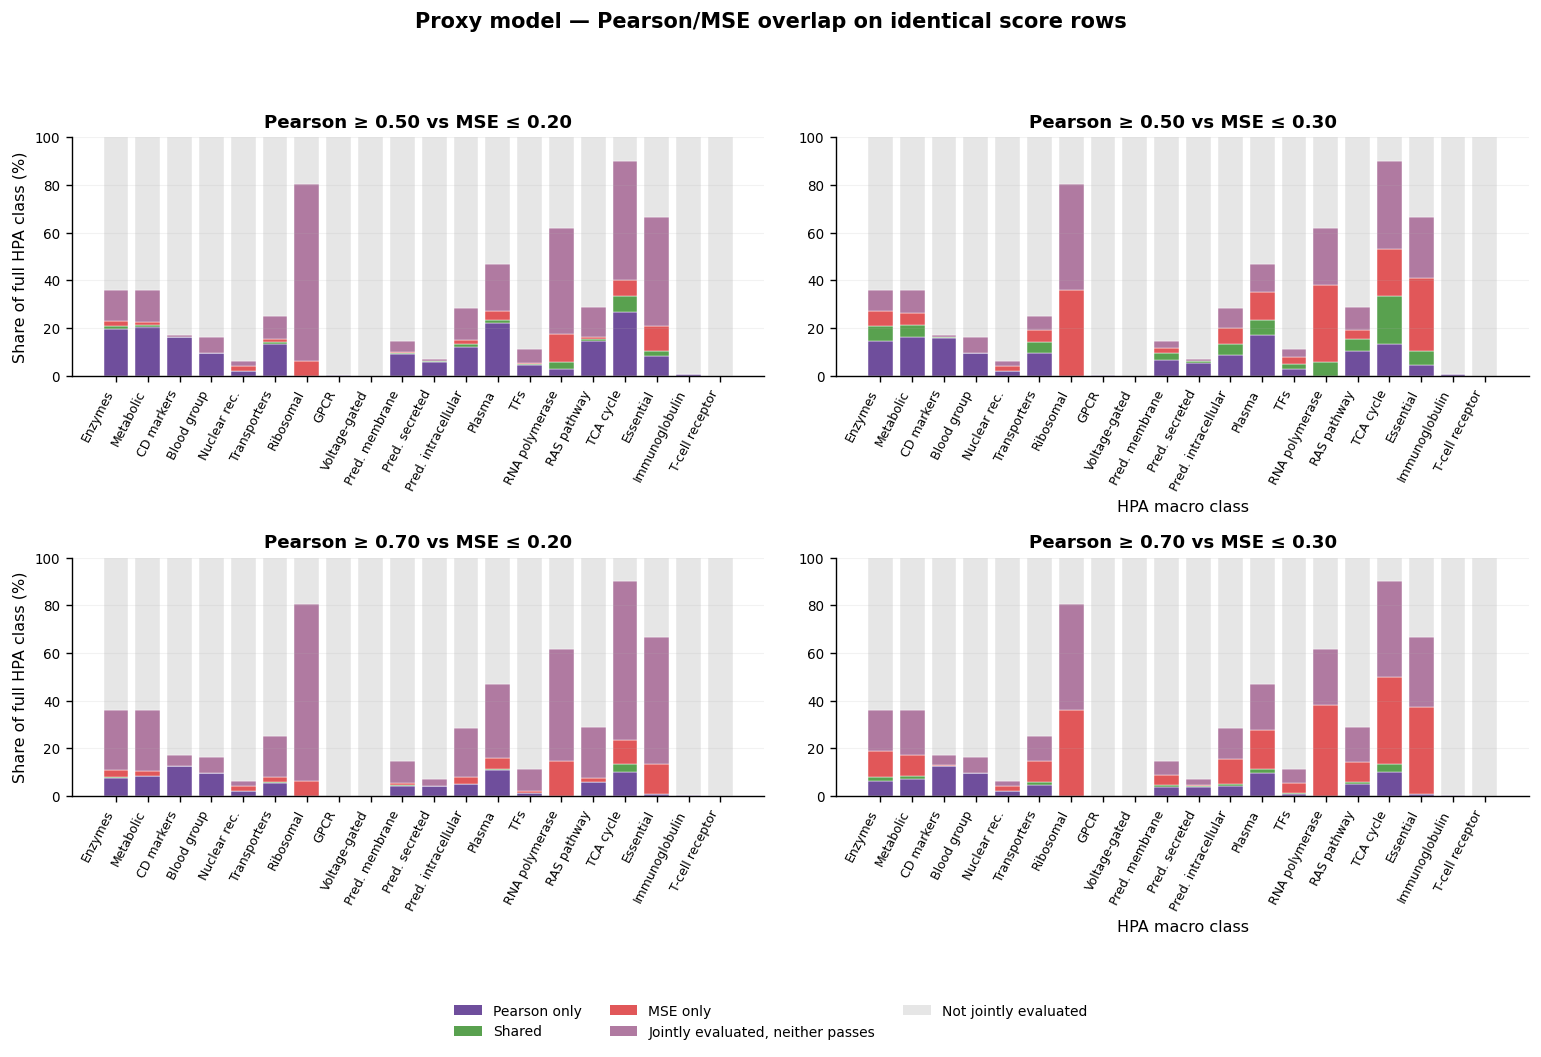

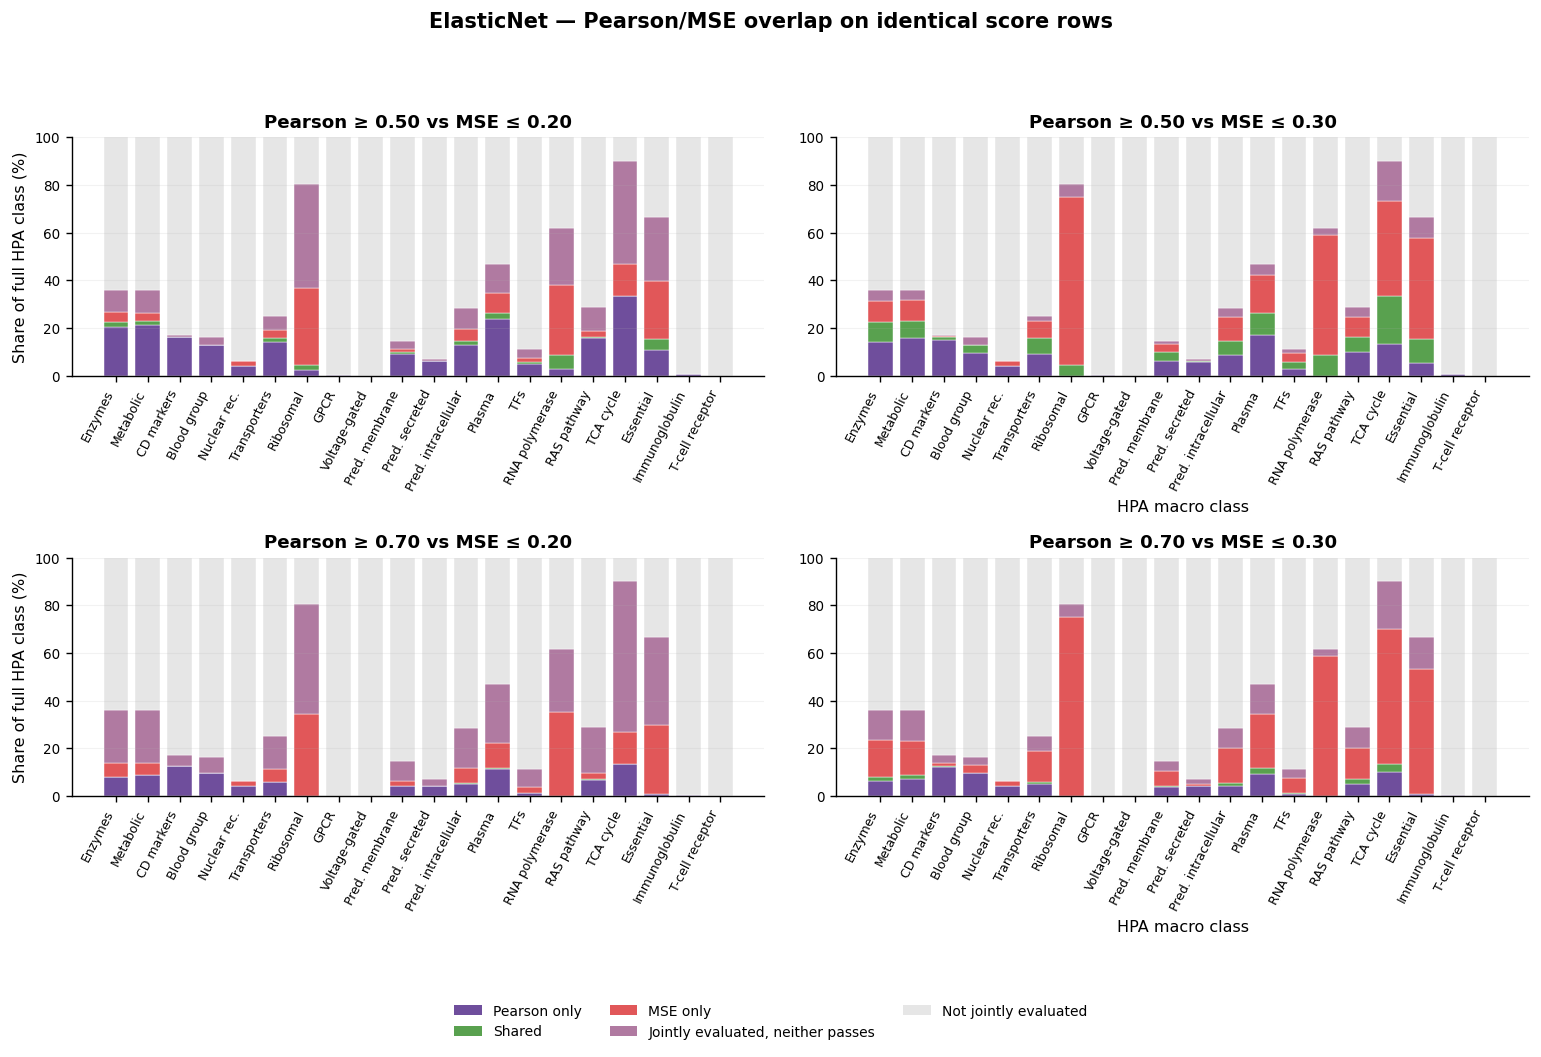

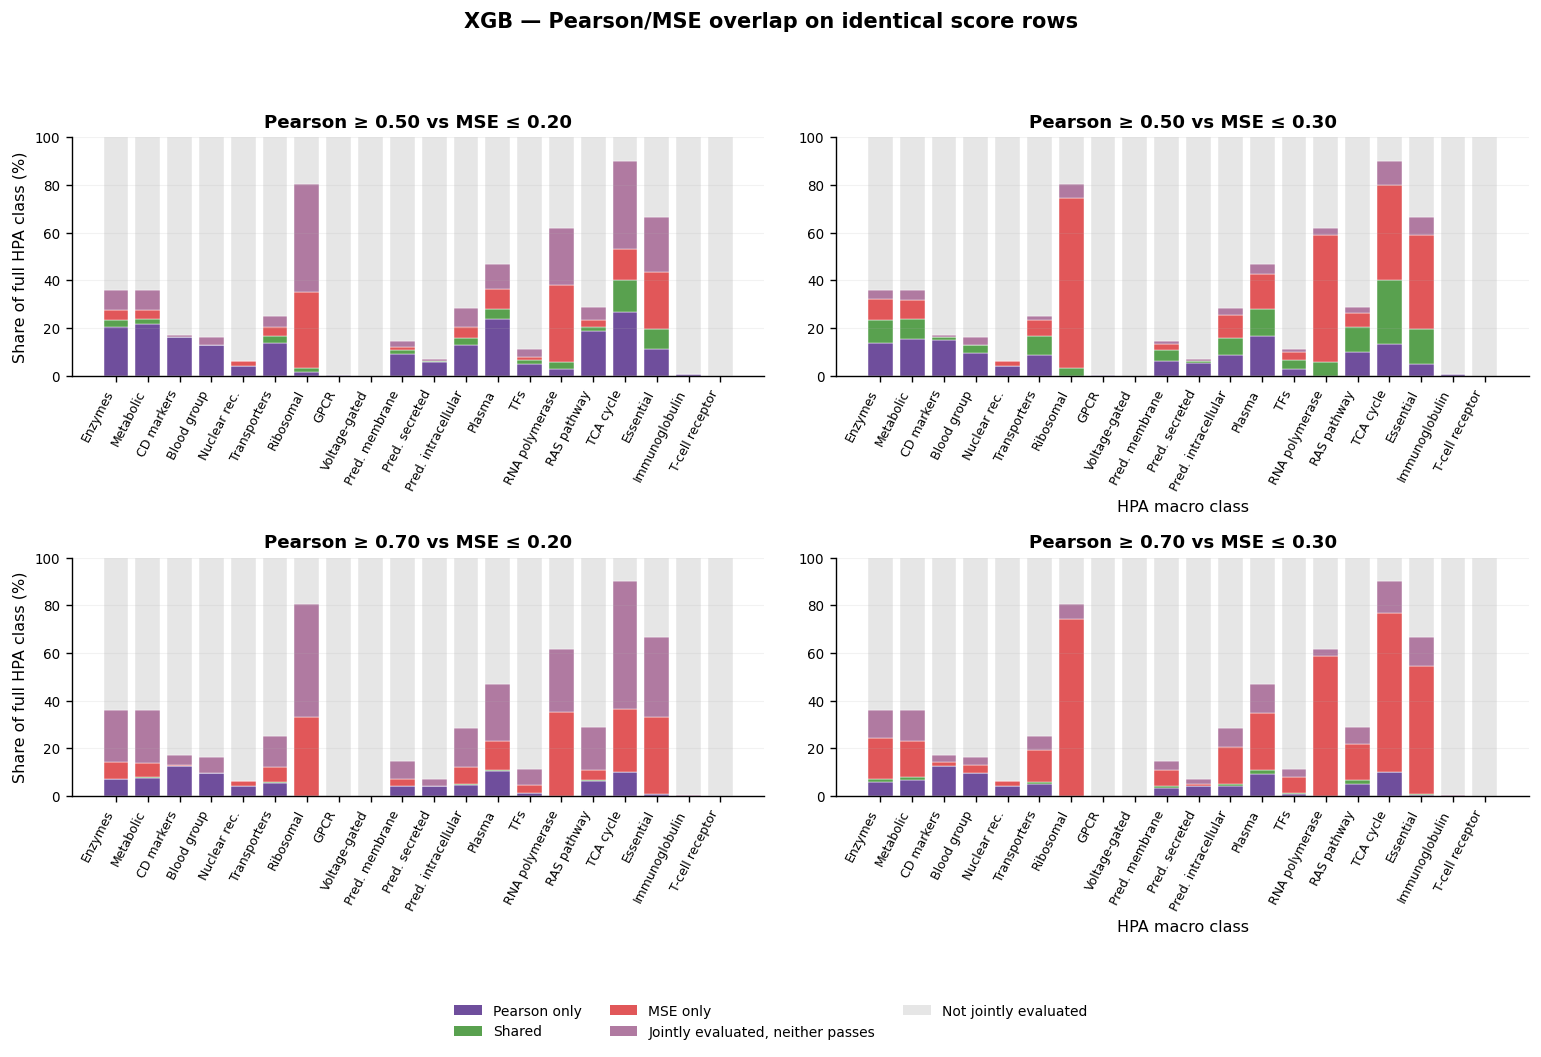

In [13]:
if INDEPENDENT_AVAILABLE:
    score_wide = independent_scores.pivot_table(
        index=['gene_symbol', 'model'], columns='metric_family', values='score', aggfunc='first'
    ).reset_index()

    raw_nesting_rows = []
    for model in MODELS:
        sub = score_wide[score_wide['model'].eq(model)]
        p_valid = sub.dropna(subset=['Pearson'])
        m_valid = sub.dropna(subset=['MSE'])
        p50 = set(p_valid.loc[p_valid['Pearson'].ge(0.50), 'gene_symbol'])
        p70 = set(p_valid.loc[p_valid['Pearson'].ge(0.70), 'gene_symbol'])
        m30 = set(m_valid.loc[m_valid['MSE'].le(0.30), 'gene_symbol'])
        m20 = set(m_valid.loc[m_valid['MSE'].le(0.20), 'gene_symbol'])
        raw_nesting_rows.extend([
            (model, 'Pearson', 0.50, 0.70, len(p50), len(p70), len(p70 - p50), len(p70 - p50) == 0),
            (model, 'MSE', 0.30, 0.20, len(m30), len(m20), len(m20 - m30), len(m20 - m30) == 0),
        ])
    independent_threshold_audit = pd.DataFrame(
        raw_nesting_rows,
        columns=['model', 'metric_family', 'loose_threshold', 'strict_threshold', 'n_loose_good', 'n_strict_good',
                 'n_strict_only_violations', 'nested_as_expected']
    )
    independent_threshold_audit.to_csv(TABLE_DIR / 'part2_raw_score_threshold_nesting_audit.csv', index=False)
    display(independent_threshold_audit)

    audit_rows, class_rows = [], []
    for model in MODELS:
        model_scores = score_wide[score_wide['model'].eq(model)].dropna(subset=['Pearson', 'MSE']).copy()
        common = set(model_scores['gene_symbol'])
        for p_thr in PEARSON_THRESHOLDS:
            for m_thr in MSE_THRESHOLDS:
                p_good = set(model_scores.loc[model_scores['Pearson'].ge(p_thr), 'gene_symbol'])
                m_good = set(model_scores.loc[model_scores['MSE'].le(m_thr), 'gene_symbol'])
                shared = p_good & m_good
                union = p_good | m_good
                n = len(common)
                expected = len(p_good) * len(m_good) / n if n else np.nan
                p_zero = probability_zero_overlap(n, len(p_good), len(m_good))
                audit_rows.append((
                    model, p_thr, m_thr, n, len(p_good), len(m_good), len(shared), len(union),
                    len(shared) / len(union) if union else 0.0, expected, p_zero,
                    zero_overlap_diagnosis(n, len(p_good), len(m_good), len(shared), p_zero)
                ))
                for hpa_class in HPA_MACRO_CLASSES:
                    class_genes = set(hpa_macro.loc[hpa_macro['hpa_macro_class'].eq(hpa_class), 'gene_symbol'])
                    c_common = class_genes & common
                    categories = {
                        'Pearson only': len((p_good - m_good) & class_genes),
                        'Shared': len(shared & class_genes),
                        'MSE only': len((m_good - p_good) & class_genes),
                        'Jointly evaluated, neither passes': len(c_common - union),
                        'Not jointly evaluated': HPA_REFERENCE_COUNTS[hpa_class] - len(c_common),
                    }
                    if categories['Not jointly evaluated'] < 0:
                        raise ValueError(f'Raw-score common universe exceeds reference HPA denominator for {hpa_class}.')
                    for component, count in categories.items():
                        class_rows.append((model, p_thr, m_thr, hpa_class, component, count, 100.0 * count / HPA_REFERENCE_COUNTS[hpa_class]))

    independent_zero_overlap_audit = pd.DataFrame(
        audit_rows,
        columns=['model', 'pearson_threshold', 'mse_threshold', 'n_common_score_rows', 'n_pearson_good', 'n_mse_good',
                 'n_shared', 'n_union', 'jaccard', 'expected_shared_if_random',
                 'probability_zero_if_random_fixed_sizes', 'diagnosis']
    )
    independent_zero_overlap_audit.to_csv(TABLE_DIR / 'part2_raw_score_pearson_mse_overlap_audit.csv', index=False)
    display(independent_zero_overlap_audit)

    independent_pearson_mse_hpa = pd.DataFrame(
        class_rows,
        columns=['model', 'pearson_threshold', 'mse_threshold', 'hpa_macro_class', 'component', 'n_genes', 'pct_of_full_hpa_class']
    )
    independent_pearson_mse_hpa.to_csv(TABLE_DIR / 'part2_raw_score_pearson_mse_hpa_overlap_percentage.csv', index=False)

    for model in MODELS:
        pairs = [(p, m) for p in PEARSON_THRESHOLDS for m in MSE_THRESHOLDS]
        fig, axes, _, _ = compact_grid(len(pairs), panel_size=VERTICAL_PANEL_SIZE, max_cols=2)
        for ax, (p_thr, m_thr) in zip(axes, pairs):
            sub = independent_pearson_mse_hpa[
                independent_pearson_mse_hpa['model'].eq(model)
                & np.isclose(independent_pearson_mse_hpa['pearson_threshold'], p_thr)
                & np.isclose(independent_pearson_mse_hpa['mse_threshold'], m_thr)
            ]
            pivot = sub.pivot_table(index='hpa_macro_class', columns='component', values='pct_of_full_hpa_class', fill_value=0)
            pivot = pivot.reindex(index=HPA_MACRO_CLASSES, columns=list(PEARSON_MSE_COLORS), fill_value=0)
            x = np.arange(len(pivot))
            bottom = np.zeros(len(pivot))
            for component, color in PEARSON_MSE_COLORS.items():
                vals = pivot[component].to_numpy(dtype=float)
                ax.bar(x, vals, bottom=bottom, width=BAR_WIDTH, color=color, edgecolor='white', linewidth=0.25)
                bottom += vals
            ax.set_ylim(0, 100)
            ax.set_ylabel('Share of full HPA class (%)')
            ax.set_title(f'Pearson ≥ {p_thr:.2f} vs MSE ≤ {m_thr:.2f}')
            _format_vertical_hpa_axis(ax)
        handles = [mpl.patches.Patch(facecolor=color, label=label) for label, color in PEARSON_MSE_COLORS.items()]
        fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.005), ncol=3, frameon=False)
        fig.suptitle(f'{model} — Pearson/MSE overlap on identical score rows', y=0.995, fontsize=12, fontweight='bold')
        fig.tight_layout(rect=(0, 0.10, 1, 0.95), h_pad=1.2, w_pad=0.8)
        stem = f'part2_{safe_filename(model)}_pearson_mse_overlap_percentage_vertical_grid'
        finish_figure(fig, stem, show=DISPLAY_MAIN_FIGURES)
        part2_figures.append(stem)

Available models: ['ElasticNet', 'Proxy model', 'XGB']
Models included: ['Proxy model', 'ElasticNet', 'XGB']

Proteomics file: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\data\proteomics_matched.joblib
Stored object type: DataFrame


**Sample-scope warning:** no test-sample list was found. The profile statistics therefore use every row in `proteomics_matched.joblib`. This tests intrinsic observed variability, but exact agreement with the evaluation metrics requires the same held-out samples.

Orientation: Kept unchanged because proteins were detected on columns.
Proteomics shape: (369, 5113)
Samples used: all 369 samples
Matched profile genes: 5,113 / 5,213


## Cross-model test: do MSE-only proteins have lower variance?

model,pearson_threshold,mse_threshold,n_mse_only,n_comparison,median_mse_only,median_comparison,relative_reduction_pct,direction_supported,p_display,FDR_BH_global
ElasticNet,0.50,0.20,810,2402,0.1994,0.6706,70.3%,True,< numerical precision,0.000e+00
ElasticNet,0.50,0.30,1742,1630,0.2532,0.8983,71.8%,True,< numerical precision,0.000e+00
ElasticNet,0.70,0.20,1071,953,0.2111,1.203,82.5%,True,< numerical precision,0.000e+00
ElasticNet,0.70,0.30,2613,791,0.2828,1.403,79.8%,True,< numerical precision,0.000e+00
Proxy model,0.50,0.20,351,2267,0.1688,0.6593,74.4%,True,1.829e-199,3.902e-199
Proxy model,0.50,0.30,1189,1654,0.2223,0.8493,73.8%,True,< numerical precision,0.000e+00
Proxy model,0.70,0.20,505,945,0.1881,1.199,84.3%,True,2.732e-216,6.398e-216
Proxy model,0.70,0.30,1819,808,0.2521,1.365,81.5%,True,< numerical precision,0.000e+00
XGB,0.50,0.20,808,2404,0.2001,0.6701,70.1%,True,< numerical precision,0.000e+00
XGB,0.50,0.30,1622,1588,0.252,0.9147,72.5%,True,< numerical precision,0.000e+00


## All directional tests

model,pearson_threshold,mse_threshold,comparison,hypothesis,metric,n_mse_only,n_comparison,median_mse_only,median_comparison,relative_reduction_pct,direction_supported,one_sided_mann_whitney_p,FDR_BH_global,FDR_BH_within_model,p_display
ElasticNet,0.50,0.20,MSE only < Pearson only,Narrower 5th–95th percentile span,observed_90pct_span,810,2402,1.443,2.67,46.0%,True,0.000e+00,0.000e+00,0.000e+00,< numerical precision
ElasticNet,0.50,0.20,MSE only < Pearson only,Narrower observed IQR,observed_iqr,810,2402,0.5646,1.023,44.8%,True,0.000e+00,0.000e+00,0.000e+00,< numerical precision
ElasticNet,0.50,0.20,MSE only < Pearson only,Lower robust MAD,observed_mad,810,2402,0.283,0.5122,44.8%,True,0.000e+00,0.000e+00,0.000e+00,< numerical precision
ElasticNet,0.50,0.20,MSE only < Pearson only,Lower observed variance,observed_variance,810,2402,0.1994,0.6706,70.3%,True,0.000e+00,0.000e+00,0.000e+00,< numerical precision
ElasticNet,0.50,0.20,MSE only < Shared,Narrower 5th–95th percentile span,observed_90pct_span,810,288,1.443,1.704,15.4%,True,8.525e-57,1.049e-56,1.049e-56,8.525e-57
ElasticNet,0.50,0.20,MSE only < Shared,Narrower observed IQR,observed_iqr,810,288,0.5646,0.6609,14.6%,True,2.170e-48,2.604e-48,2.572e-48,2.170e-48
ElasticNet,0.50,0.20,MSE only < Shared,Lower robust MAD,observed_mad,810,288,0.283,0.331,14.5%,True,4.021e-48,4.766e-48,4.596e-48,4.021e-48
ElasticNet,0.50,0.20,MSE only < Shared,Lower observed variance,observed_variance,810,288,0.1994,0.2797,28.7%,True,1.025e-58,1.279e-58,1.313e-58,1.025e-58
ElasticNet,0.50,0.30,MSE only < Pearson only,Narrower 5th–95th percentile span,observed_90pct_span,1742,1630,1.626,3.089,47.4%,True,0.000e+00,0.000e+00,0.000e+00,< numerical precision
ElasticNet,0.50,0.30,MSE only < Pearson only,Narrower observed IQR,observed_iqr,1742,1630,0.6412,1.182,45.7%,True,0.000e+00,0.000e+00,0.000e+00,< numerical precision


## Most MSE-only-dominated HPA classes across all models

model,pearson_threshold,mse_threshold,hpa_macro_class,Pearson only,Shared,MSE only,Neither passes,jointly_evaluated_n,successful_n,mse_only_pct_of_joint,mse_only_pct_of_successes,n_genes,median_observed_variance,median_variance_percentile,median_observed_iqr,median_observed_90pct_span,median_observed_mad
ElasticNet,0.50,0.20,Ribosomal proteins,4,4,58,79,145,66,40.0%,87.9%,58,0.2042,9.8,0.5567,1.463,0.2803
ElasticNet,0.50,0.20,RNA polymerase related proteins,1,2,10,8,21,13,47.6%,76.9%,10,0.1813,6.1,0.5211,1.409,0.2602
ElasticNet,0.50,0.20,Essential proteins,220,94,487,547,1348,801,36.1%,60.8%,487,0.1927,7.6,0.5596,1.415,0.2783
ElasticNet,0.50,0.20,Citric acid cycle related proteins,10,0,4,13,27,14,14.8%,28.6%,4,0.2405,17.2,0.641,1.583,0.3252
ElasticNet,0.50,0.20,Predicted intracellular proteins,2062,260,761,1449,4532,3083,16.8%,24.7%,761,0.1991,8.7,0.5641,1.441,0.282
ElasticNet,0.50,0.20,Plasma proteins,884,100,315,464,1763,1299,17.9%,24.2%,315,0.1953,8.1,0.56,1.416,0.2795
ElasticNet,0.50,0.20,Transcription factors,72,13,24,56,165,109,14.5%,22.0%,24,0.2248,13.5,0.6118,1.534,0.3049
ElasticNet,0.50,0.20,Transporters,297,44,72,122,535,413,13.5%,17.4%,72,0.198,8.6,0.5656,1.437,0.2827
ElasticNet,0.50,0.30,Ribosomal proteins,0,8,127,10,145,135,87.6%,94.1%,127,0.2315,14.8,0.6159,1.564,0.3064
ElasticNet,0.50,0.30,RNA polymerase related proteins,0,3,17,1,21,20,81.0%,85.0%,17,0.197,8.4,0.5699,1.476,0.2853


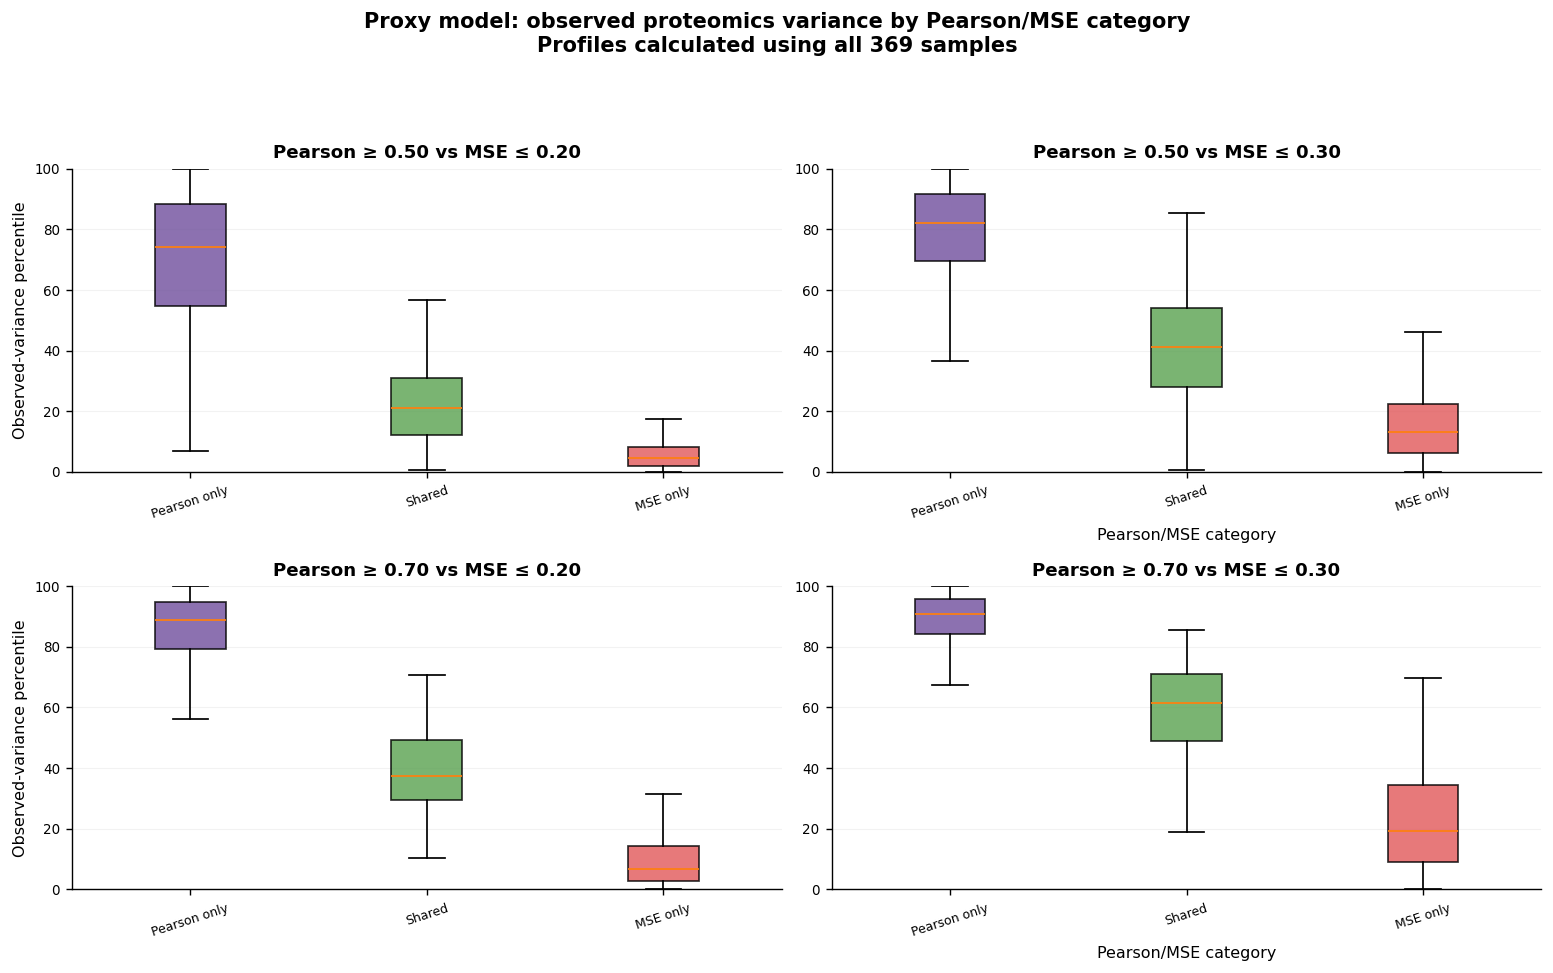

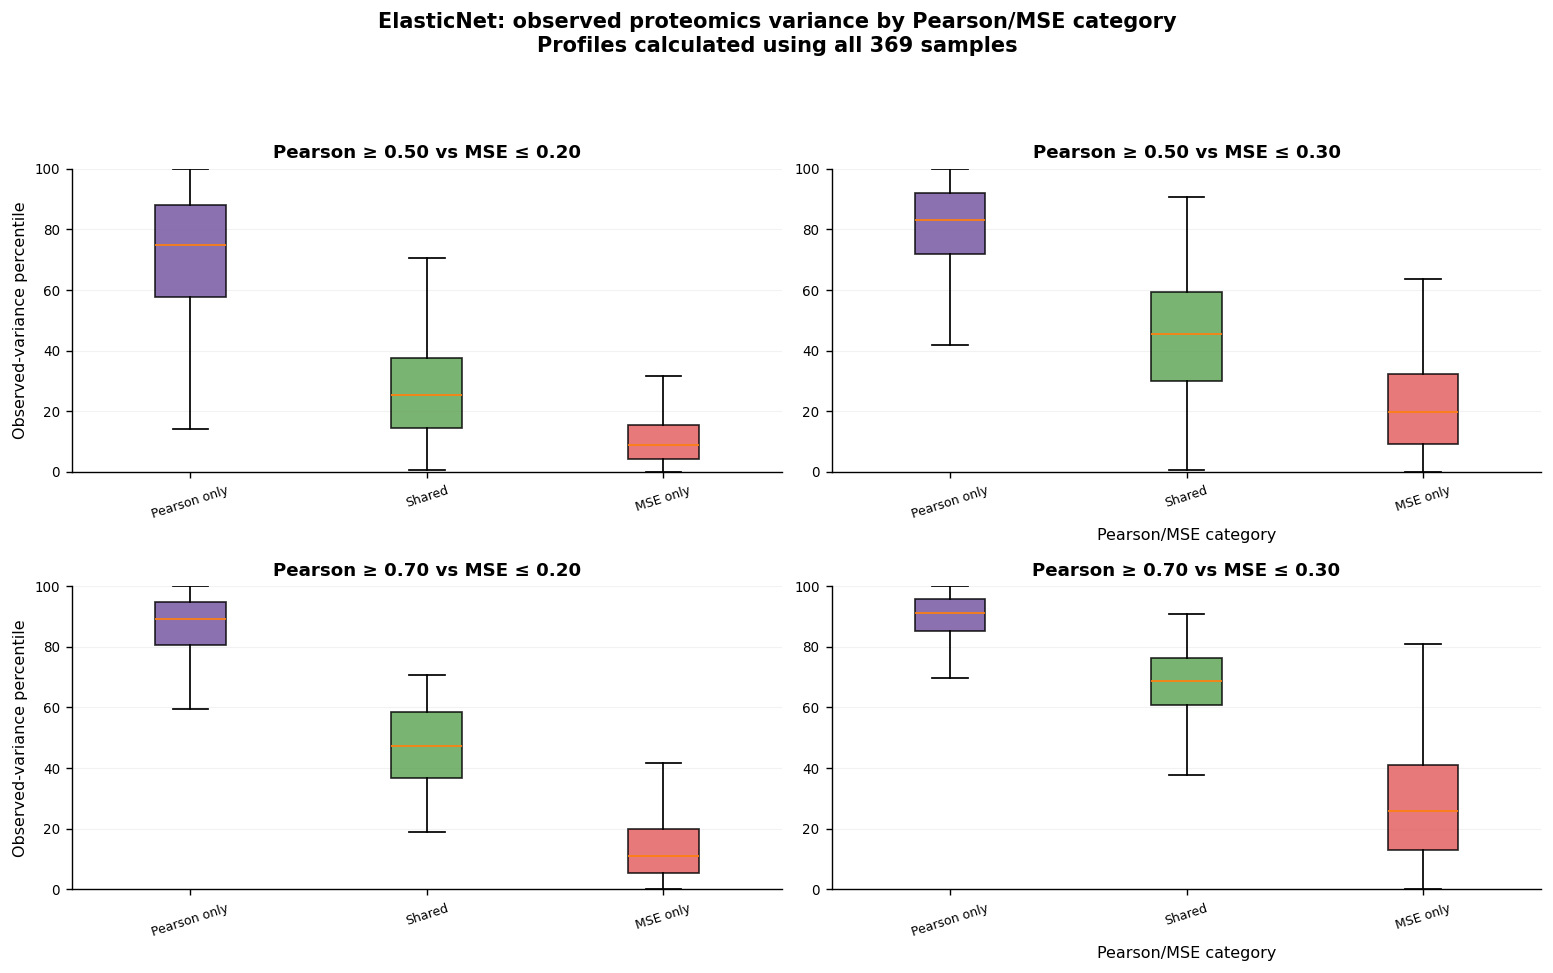

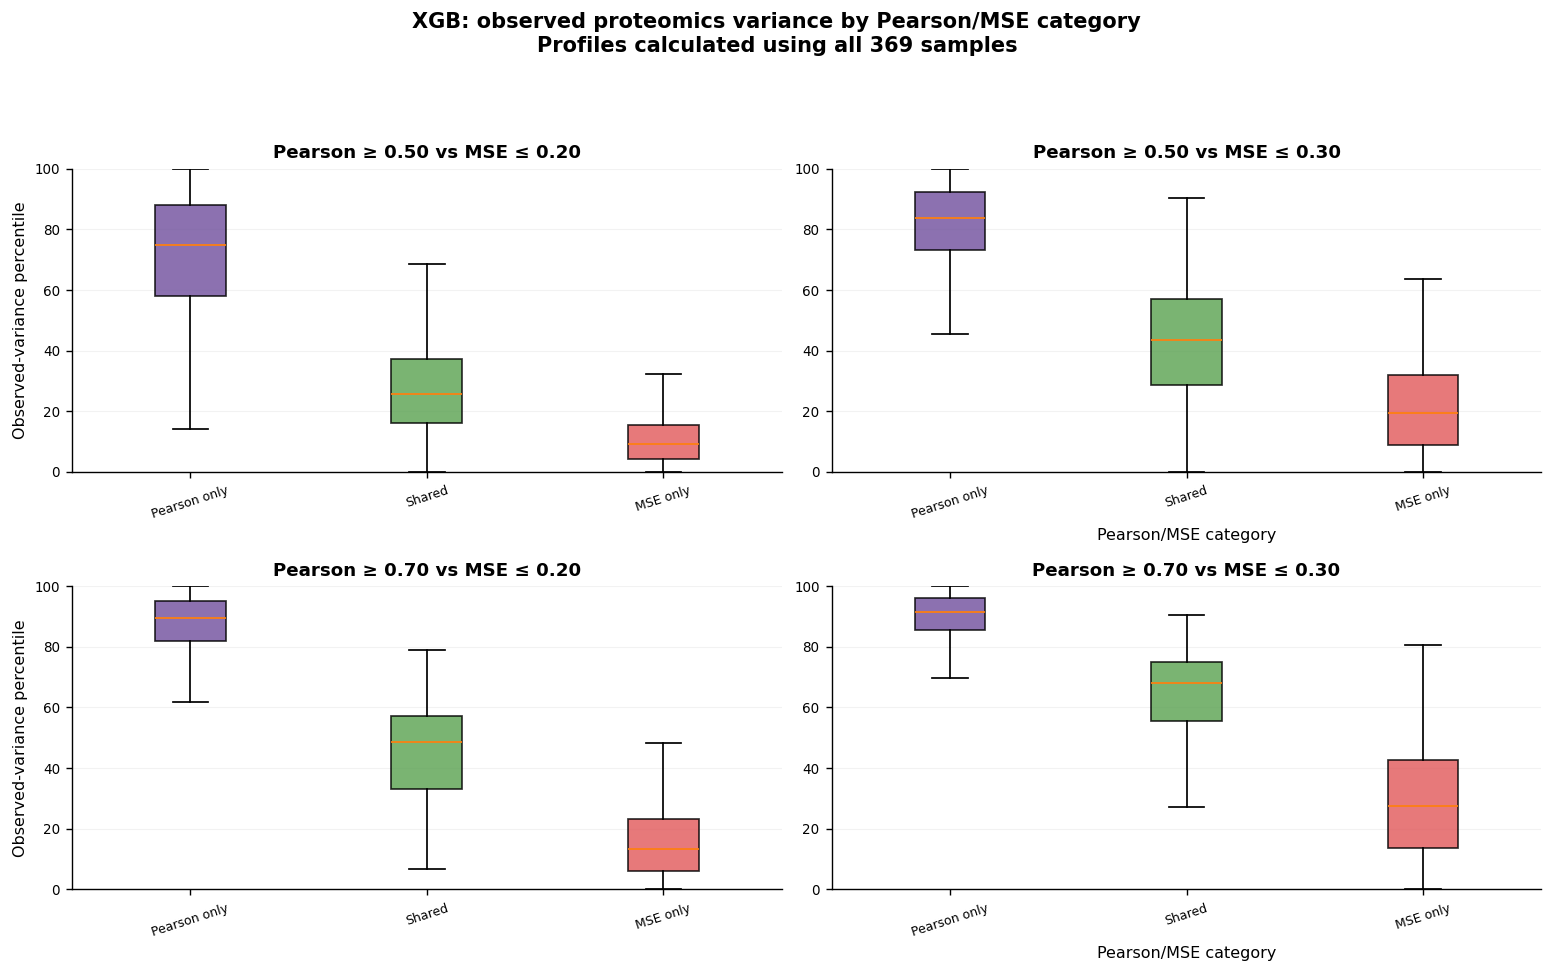

**Scale not confirmed:** `mean_baseline_mse` equals the observed population variance, but it should not be compared directly with MSE cut-offs 0.20 or 0.30 until the matrix scale is confirmed to match the score calculation.


Interpretation guide:
1. For each model, inspect the rows with `comparison = MSE only < Pearson only`.
2. The low-variance explanation is supported when `median_mse_only < median_comparison`, `direction_supported = True`, and FDR < 0.05.
3. The MSE-only < Shared comparison tests whether low variance also distinguishes MSE-only proteins from proteins passing both metrics.
4. Compare the relative-reduction percentages across Proxy, ElasticNet, and XGB rather than comparing p-values alone.
5. Observed variance and mean-baseline MSE are numerically the same quantity here and must not be reported as independent evidence.
6. This cell tests observed target variability. Testing whether model predictions collapse toward the mean still requires the sample-level prediction matrices for each model.


In [16]:
# =============================================================================
# LOW-VARIANCE DIAGNOSTIC FOR ALL THREE MODELS
#
# Models:
#   - Proxy model
#   - ElasticNet
#   - XGB
#
# File:
#   data/proteomics_matched.joblib
#
# Main question:
#   Do MSE-only proteins have lower observed cross-sample variability than
#   Pearson-only and Shared proteins?
# =============================================================================

from pathlib import Path
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu
from IPython.display import display, Markdown


# -----------------------------------------------------------------------------
# Settings
# -----------------------------------------------------------------------------
BASE_DIR = Path(globals().get("BASE_DIR", Path.cwd()))

PROTEOMICS_PATH = (
    BASE_DIR
    / "data"
    / "proteomics_matched.joblib"
)

MODELS_TO_CHECK = [
    "Proxy model",
    "ElasticNet",
    "XGB",
]

PEARSON_THRESHOLDS_DIAG = [
    0.50,
    0.70,
]

MSE_THRESHOLDS_DIAG = [
    0.20,
    0.30,
]

MIN_N_FOR_TEST = 5
TOP_RED_CLASSES_PER_CASE = 8

# Set to True only when proteomics_matched.joblib is on exactly the same
# scale and transformation used to calculate the reported MSE values.
PROTEOMICS_IS_ON_MSE_SCALE = False

# Optional exact test-sample identifiers.
#
# Example:
# PROFILE_SAMPLE_IDS = test_sample_names
#
# When None, the cell tries common variable names and otherwise uses all rows.
PROFILE_SAMPLE_IDS = globals().get(
    "PROFILE_SAMPLE_IDS",
    None,
)

OUTPUT_TABLE_DIR = Path(
    globals().get(
        "TABLE_DIR",
        BASE_DIR / "diagnostic_tables",
    )
)

OUTPUT_FIGURE_DIR = Path(
    globals().get(
        "FIGURE_DIR",
        BASE_DIR / "diagnostic_figures",
    )
)

OUTPUT_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# -----------------------------------------------------------------------------
# Check required notebook objects
# -----------------------------------------------------------------------------
if "score_wide" not in globals():

    if "independent_scores" not in globals():

        raise NameError(
            "Run the notebook from the beginning through the independent-score "
            "section first. The diagnostic requires `independent_scores` or "
            "`score_wide`."
        )

    score_wide = (
        independent_scores
        .pivot_table(
            index=[
                "gene_symbol",
                "model",
            ],
            columns="metric_family",
            values="score",
            aggfunc="first",
        )
        .reset_index()
    )


for required_name in [
    "hpa_macro",
    "HPA_MACRO_CLASSES",
]:

    if required_name not in globals():

        raise NameError(
            f"Missing `{required_name}`. "
            "Run the preceding HPA-loading cells first."
        )


required_score_columns = {
    "gene_symbol",
    "model",
    "Pearson",
    "MSE",
}

if not required_score_columns.issubset(
    score_wide.columns
):

    raise ValueError(
        "score_wide does not contain the required columns. "
        f"Available columns: {list(score_wide.columns)}"
    )


available_models = sorted(
    score_wide["model"]
    .dropna()
    .astype(str)
    .unique()
)

models_found = [
    model
    for model in MODELS_TO_CHECK
    if model in available_models
]

missing_models = [
    model
    for model in MODELS_TO_CHECK
    if model not in available_models
]

print(
    "Available models:",
    available_models,
)

print(
    "Models included:",
    models_found,
)

if missing_models:

    print(
        "Models not found and skipped:",
        missing_models,
    )

if not models_found:

    raise ValueError(
        "None of the requested models was found in score_wide."
    )


# -----------------------------------------------------------------------------
# Identifier cleaning
# -----------------------------------------------------------------------------
def diagnostic_clean_gene(value):

    if "clean_gene_symbol" in globals():

        return clean_gene_symbol(value)

    if pd.isna(value):

        return np.nan

    text = str(value).strip()

    if not text:

        return np.nan

    return re.split(
        r"[;|,/\s]+",
        text,
    )[0].upper()


score_wide = score_wide.copy()

score_wide["gene_symbol"] = (
    score_wide["gene_symbol"]
    .map(diagnostic_clean_gene)
)

score_wide["Pearson"] = pd.to_numeric(
    score_wide["Pearson"],
    errors="coerce",
)

score_wide["MSE"] = pd.to_numeric(
    score_wide["MSE"],
    errors="coerce",
)


# -----------------------------------------------------------------------------
# Load the proteomics matrix
# -----------------------------------------------------------------------------
if not PROTEOMICS_PATH.exists():

    candidates = sorted(
        BASE_DIR.rglob(
            "proteomics_matched.joblib"
        ),
        key=lambda path: (
            len(path.parts),
            str(path),
        ),
    )

    if not candidates:

        raise FileNotFoundError(
            "proteomics_matched.joblib was not found. "
            "Expected location:\n"
            f"{PROTEOMICS_PATH}"
        )

    PROTEOMICS_PATH = candidates[0]


loaded_object = joblib.load(
    PROTEOMICS_PATH
)

print(
    "\nProteomics file:",
    PROTEOMICS_PATH,
)

print(
    "Stored object type:",
    type(loaded_object).__name__,
)


def extract_dataframe(obj):
    """
    Extract a labeled DataFrame from common joblib structures.
    """

    if isinstance(
        obj,
        pd.DataFrame,
    ):

        return obj.copy()

    if isinstance(
        obj,
        dict,
    ):

        preferred_keys = [
            "proteomics_matched",
            "proteomics",
            "matrix",
            "data",
            "values",
            "Y",
            "y",
        ]

        key_map = {
            str(key).casefold(): key
            for key in obj
        }

        for candidate in preferred_keys:

            key = key_map.get(
                candidate.casefold()
            )

            if (
                key is not None
                and isinstance(
                    obj[key],
                    pd.DataFrame,
                )
            ):

                return obj[key].copy()

        for value in obj.values():

            if isinstance(
                value,
                pd.DataFrame,
            ):

                return value.copy()

    if isinstance(
        obj,
        (list, tuple),
    ):

        for value in obj:

            if isinstance(
                value,
                pd.DataFrame,
            ):

                return value.copy()

    raise TypeError(
        "The joblib must contain a labeled pandas DataFrame. "
        "The expected orientation is samples × proteins."
    )


proteomics = extract_dataframe(
    loaded_object
)


# -----------------------------------------------------------------------------
# Detect orientation
# -----------------------------------------------------------------------------
all_score_genes = set(
    score_wide["gene_symbol"]
    .dropna()
)

clean_columns = [
    diagnostic_clean_gene(value)
    for value in proteomics.columns
]

clean_index = [
    diagnostic_clean_gene(value)
    for value in proteomics.index
]

column_overlap = sum(
    gene in all_score_genes
    for gene in clean_columns
    if pd.notna(gene)
)

index_overlap = sum(
    gene in all_score_genes
    for gene in clean_index
    if pd.notna(gene)
)


if index_overlap > column_overlap:

    proteomics = proteomics.T

    orientation_message = (
        "Transposed because proteins were detected on rows."
    )

else:

    orientation_message = (
        "Kept unchanged because proteins were detected on columns."
    )


proteomics.columns = [
    diagnostic_clean_gene(value)
    for value in proteomics.columns
]

valid_columns = [
    pd.notna(value)
    for value in proteomics.columns
]

proteomics = proteomics.loc[
    :,
    valid_columns,
]

proteomics = proteomics.apply(
    pd.to_numeric,
    errors="coerce",
)


# Multiple protein columns can map to one cleaned gene symbol.
if proteomics.columns.duplicated().any():

    duplicate_count = int(
        proteomics.columns
        .duplicated()
        .sum()
    )

    print(
        f"Aggregating {duplicate_count:,} duplicate "
        "gene-symbol columns by median."
    )

    proteomics = (
        proteomics.T
        .groupby(level=0)
        .median()
        .T
    )


# -----------------------------------------------------------------------------
# Restrict to test samples when identifiers are available
# -----------------------------------------------------------------------------
if PROFILE_SAMPLE_IDS is None:

    for candidate_name in [
        "TEST_SAMPLE_IDS",
        "test_sample_ids",
        "test_samples",
        "H5_TEST_SAMPLES",
        "h5_test_samples",
    ]:

        if (
            candidate_name in globals()
            and globals()[candidate_name] is not None
        ):

            PROFILE_SAMPLE_IDS = list(
                globals()[candidate_name]
            )

            print(
                f"Using test samples from `{candidate_name}`."
            )

            break


if PROFILE_SAMPLE_IDS is not None:

    requested_samples = [
        str(value)
        for value in PROFILE_SAMPLE_IDS
    ]

    matrix_samples = [
        str(value)
        for value in proteomics.index
    ]

    position_by_sample = {
        sample: position
        for position, sample
        in enumerate(matrix_samples)
    }

    matched_samples = [
        sample
        for sample in requested_samples
        if sample in position_by_sample
    ]

    if len(matched_samples) < 3:

        raise ValueError(
            "Fewer than three requested test samples matched "
            "the proteomics matrix row index."
        )

    proteomics = proteomics.iloc[
        [
            position_by_sample[sample]
            for sample in matched_samples
        ]
    ]

    sample_scope = (
        f"{len(matched_samples):,} matched test samples"
    )

else:

    sample_scope = (
        f"all {len(proteomics):,} samples"
    )

    display(
        Markdown(
            "**Sample-scope warning:** no test-sample list was found. "
            "The profile statistics therefore use every row in "
            "`proteomics_matched.joblib`. This tests intrinsic observed "
            "variability, but exact agreement with the evaluation metrics "
            "requires the same held-out samples."
        )
    )


print(
    "Orientation:",
    orientation_message,
)

print(
    "Proteomics shape:",
    proteomics.shape,
)

print(
    "Samples used:",
    sample_scope,
)


# -----------------------------------------------------------------------------
# Compute one observed-profile table shared by all models
# -----------------------------------------------------------------------------
matched_genes = sorted(
    all_score_genes
    & set(proteomics.columns)
)

if not matched_genes:

    raise ValueError(
        "No score-table genes matched the proteomics columns. "
        "Check whether the matrix columns contain gene symbols."
    )


profile_rows = []

for gene in matched_genes:

    values = (
        proteomics[gene]
        .dropna()
        .to_numpy(
            dtype=float
        )
    )

    if len(values) < 3:

        continue

    q05, q25, q75, q95 = np.quantile(
        values,
        [
            0.05,
            0.25,
            0.75,
            0.95,
        ],
    )

    mean_value = float(
        np.mean(values)
    )

    median_value = float(
        np.median(values)
    )

    # Population variance equals the MSE of predicting the protein mean
    # for every sample.
    observed_variance = float(
        np.mean(
            (
                values
                - mean_value
            ) ** 2
        )
    )

    profile_rows.append({
        "gene_symbol": gene,

        "n_profile_samples": len(values),

        "missing_fraction": float(
            proteomics[gene]
            .isna()
            .mean()
        ),

        "observed_mean": mean_value,

        "observed_median": median_value,

        "observed_variance": observed_variance,

        "observed_sd": float(
            np.sqrt(
                observed_variance
            )
        ),

        "observed_iqr": float(
            q75 - q25
        ),

        "observed_90pct_span": float(
            q95 - q05
        ),

        "observed_range": float(
            np.max(values)
            - np.min(values)
        ),

        "observed_mad": float(
            np.median(
                np.abs(
                    values
                    - median_value
                )
            )
        ),

        # Same numeric value as population variance.
        "mean_baseline_mse": observed_variance,
    })


profile_metrics = pd.DataFrame(
    profile_rows
)


for metric in [
    "observed_variance",
    "observed_sd",
    "observed_iqr",
    "observed_90pct_span",
    "observed_range",
    "observed_mad",
]:

    profile_metrics[
        f"{metric}_percentile"
    ] = (
        100
        * profile_metrics[metric]
        .rank(
            method="average",
            pct=True,
        )
    )


profile_gene_set = set(
    profile_metrics["gene_symbol"]
)


print(
    f"Matched profile genes: "
    f"{len(profile_gene_set):,} / "
    f"{len(all_score_genes):,}"
)


# -----------------------------------------------------------------------------
# Detect per-protein z-scoring
# -----------------------------------------------------------------------------
fraction_variance_near_one = (
    profile_metrics[
        "observed_variance"
    ]
    .between(
        0.90,
        1.10,
    )
    .mean()
)


if fraction_variance_near_one >= 0.80:

    display(
        Markdown(
            "**Standardization warning:** at least 80% of proteins have "
            "variance between 0.90 and 1.10. The matrix may have been "
            "z-scored separately for each protein. If so, between-protein "
            "variance differences have been removed and this diagnostic "
            "cannot test the low-variance hypothesis reliably."
        )
    )


# -----------------------------------------------------------------------------
# Benjamini-Hochberg correction
# -----------------------------------------------------------------------------
def bh_adjust(p_values):

    p_values = np.asarray(
        p_values,
        dtype=float,
    )

    output = np.full(
        len(p_values),
        np.nan,
    )

    valid = np.isfinite(
        p_values
    )

    if not valid.any():

        return output

    valid_values = p_values[
        valid
    ]

    order = np.argsort(
        valid_values
    )

    ranked = valid_values[
        order
    ]

    adjusted = (
        ranked
        * len(ranked)
        / np.arange(
            1,
            len(ranked) + 1,
        )
    )

    adjusted = np.minimum.accumulate(
        adjusted[::-1]
    )[::-1]

    adjusted = np.clip(
        adjusted,
        0,
        1,
    )

    restored = np.empty_like(
        adjusted
    )

    restored[order] = adjusted

    output[
        np.where(valid)[0]
    ] = restored

    return output


# -----------------------------------------------------------------------------
# Build categories and tests for every model and threshold combination
# -----------------------------------------------------------------------------
CATEGORY_ORDER = [
    "Pearson only",
    "Shared",
    "MSE only",
    "Neither passes",
]

TEST_METRICS = [
    (
        "Lower observed variance",
        "observed_variance",
    ),
    (
        "Narrower observed IQR",
        "observed_iqr",
    ),
    (
        "Narrower 5th–95th percentile span",
        "observed_90pct_span",
    ),
    (
        "Lower robust MAD",
        "observed_mad",
    ),
]

membership_parts = []
category_summary_parts = []
test_rows = []
class_count_parts = []
class_profile_parts = []


for model in models_found:

    model_scores = (
        score_wide[
            score_wide["model"].eq(model)
        ]
        .dropna(
            subset=[
                "gene_symbol",
                "Pearson",
                "MSE",
            ]
        )
        .copy()
    )

    # One row per gene and model.
    model_scores = (
        model_scores
        .groupby(
            "gene_symbol",
            as_index=False,
        )
        .agg(
            Pearson=(
                "Pearson",
                "max",
            ),
            MSE=(
                "MSE",
                "min",
            ),
        )
    )

    common_profile_genes = (
        set(model_scores["gene_symbol"])
        & profile_gene_set
    )

    for pearson_threshold in PEARSON_THRESHOLDS_DIAG:

        for mse_threshold in MSE_THRESHOLDS_DIAG:

            pearson_good = (
                set(
                    model_scores.loc[
                        model_scores["Pearson"].ge(
                            pearson_threshold
                        ),
                        "gene_symbol",
                    ]
                )
                & common_profile_genes
            )

            mse_good = (
                set(
                    model_scores.loc[
                        model_scores["MSE"].le(
                            mse_threshold
                        ),
                        "gene_symbol",
                    ]
                )
                & common_profile_genes
            )

            membership_rows = []

            for gene in sorted(
                common_profile_genes
            ):

                pearson_pass = (
                    gene in pearson_good
                )

                mse_pass = (
                    gene in mse_good
                )

                if pearson_pass and mse_pass:

                    category = "Shared"

                elif pearson_pass:

                    category = "Pearson only"

                elif mse_pass:

                    category = "MSE only"

                else:

                    category = "Neither passes"

                membership_rows.append({
                    "model": model,
                    "pearson_threshold": pearson_threshold,
                    "mse_threshold": mse_threshold,
                    "gene_symbol": gene,
                    "category": category,
                })

            membership = pd.DataFrame(
                membership_rows
            )

            membership_parts.append(
                membership
            )

            merged = membership.merge(
                profile_metrics,
                on="gene_symbol",
                how="left",
            )

            # -------------------------------------------------------------
            # Category-level profile summary
            # -------------------------------------------------------------
            category_summary = (
                merged
                .groupby(
                    "category",
                    observed=True,
                )
                .agg(
                    n_genes=(
                        "gene_symbol",
                        "nunique",
                    ),

                    median_observed_variance=(
                        "observed_variance",
                        "median",
                    ),

                    median_variance_percentile=(
                        "observed_variance_percentile",
                        "median",
                    ),

                    median_observed_sd=(
                        "observed_sd",
                        "median",
                    ),

                    median_observed_iqr=(
                        "observed_iqr",
                        "median",
                    ),

                    median_observed_90pct_span=(
                        "observed_90pct_span",
                        "median",
                    ),

                    median_observed_mad=(
                        "observed_mad",
                        "median",
                    ),

                    median_mean_baseline_mse=(
                        "mean_baseline_mse",
                        "median",
                    ),
                )
                .reindex(
                    CATEGORY_ORDER
                )
                .dropna(
                    how="all"
                )
                .reset_index()
            )

            category_summary.insert(
                0,
                "mse_threshold",
                mse_threshold,
            )

            category_summary.insert(
                0,
                "pearson_threshold",
                pearson_threshold,
            )

            category_summary.insert(
                0,
                "model",
                model,
            )

            category_summary_parts.append(
                category_summary
            )

            # -------------------------------------------------------------
            # Directional tests
            #
            # H1: MSE-only values are smaller than the comparison group.
            # -------------------------------------------------------------
            for comparison_category in [
                "Pearson only",
                "Shared",
            ]:

                for hypothesis, metric in TEST_METRICS:

                    mse_only_values = (
                        merged.loc[
                            merged["category"].eq(
                                "MSE only"
                            ),
                            metric,
                        ]
                        .dropna()
                    )

                    comparison_values = (
                        merged.loc[
                            merged["category"].eq(
                                comparison_category
                            ),
                            metric,
                        ]
                        .dropna()
                    )

                    if (
                        len(mse_only_values)
                        >= MIN_N_FOR_TEST
                        and len(comparison_values)
                        >= MIN_N_FOR_TEST
                    ):

                        test_result = mannwhitneyu(
                            mse_only_values,
                            comparison_values,
                            alternative="less",
                        )

                        p_value = float(
                            test_result.pvalue
                        )

                    else:

                        p_value = np.nan

                    median_mse_only = (
                        float(
                            mse_only_values.median()
                        )
                        if len(mse_only_values)
                        else np.nan
                    )

                    median_comparison = (
                        float(
                            comparison_values.median()
                        )
                        if len(comparison_values)
                        else np.nan
                    )

                    reduction_pct = (
                        100
                        * (
                            median_comparison
                            - median_mse_only
                        )
                        / median_comparison
                        if (
                            np.isfinite(median_comparison)
                            and median_comparison != 0
                            and np.isfinite(median_mse_only)
                        )
                        else np.nan
                    )

                    test_rows.append({
                        "model": model,
                        "pearson_threshold": pearson_threshold,
                        "mse_threshold": mse_threshold,

                        "comparison": (
                            f"MSE only < "
                            f"{comparison_category}"
                        ),

                        "hypothesis": hypothesis,
                        "metric": metric,

                        "n_mse_only": len(
                            mse_only_values
                        ),

                        "n_comparison": len(
                            comparison_values
                        ),

                        "median_mse_only": median_mse_only,
                        "median_comparison": median_comparison,
                        "relative_reduction_pct": reduction_pct,

                        "direction_supported": (
                            median_mse_only
                            < median_comparison
                            if (
                                np.isfinite(median_mse_only)
                                and np.isfinite(median_comparison)
                            )
                            else False
                        ),

                        "one_sided_mann_whitney_p": p_value,
                    })

            # -------------------------------------------------------------
            # HPA-class counts
            # -------------------------------------------------------------
            class_merged = merged.merge(
                hpa_macro[
                    [
                        "gene_symbol",
                        "hpa_macro_class",
                    ]
                ]
                .drop_duplicates(),
                on="gene_symbol",
                how="inner",
            )

            class_counts = (
                class_merged
                .groupby(
                    [
                        "hpa_macro_class",
                        "category",
                    ],
                    observed=True,
                )["gene_symbol"]
                .nunique()
                .unstack(
                    fill_value=0
                )
                .reindex(
                    index=HPA_MACRO_CLASSES,
                    columns=CATEGORY_ORDER,
                    fill_value=0,
                )
            )

            class_counts["jointly_evaluated_n"] = (
                class_counts[
                    CATEGORY_ORDER
                ]
                .sum(
                    axis=1
                )
            )

            class_counts["successful_n"] = (
                class_counts[
                    [
                        "Pearson only",
                        "Shared",
                        "MSE only",
                    ]
                ]
                .sum(
                    axis=1
                )
            )

            class_counts["mse_only_pct_of_joint"] = np.where(
                class_counts["jointly_evaluated_n"] > 0,
                (
                    100
                    * class_counts["MSE only"]
                    / class_counts["jointly_evaluated_n"]
                ),
                np.nan,
            )

            class_counts["mse_only_pct_of_successes"] = np.where(
                class_counts["successful_n"] > 0,
                (
                    100
                    * class_counts["MSE only"]
                    / class_counts["successful_n"]
                ),
                np.nan,
            )

            class_counts = class_counts.reset_index()

            class_counts.insert(
                0,
                "mse_threshold",
                mse_threshold,
            )

            class_counts.insert(
                0,
                "pearson_threshold",
                pearson_threshold,
            )

            class_counts.insert(
                0,
                "model",
                model,
            )

            class_count_parts.append(
                class_counts
            )

            # -------------------------------------------------------------
            # HPA-class profile summary
            # -------------------------------------------------------------
            class_profiles = (
                class_merged
                .groupby(
                    [
                        "hpa_macro_class",
                        "category",
                    ],
                    observed=True,
                )
                .agg(
                    n_genes=(
                        "gene_symbol",
                        "nunique",
                    ),

                    median_observed_variance=(
                        "observed_variance",
                        "median",
                    ),

                    median_variance_percentile=(
                        "observed_variance_percentile",
                        "median",
                    ),

                    median_observed_iqr=(
                        "observed_iqr",
                        "median",
                    ),

                    median_observed_90pct_span=(
                        "observed_90pct_span",
                        "median",
                    ),

                    median_observed_mad=(
                        "observed_mad",
                        "median",
                    ),
                )
                .reset_index()
            )

            class_profiles.insert(
                0,
                "mse_threshold",
                mse_threshold,
            )

            class_profiles.insert(
                0,
                "pearson_threshold",
                pearson_threshold,
            )

            class_profiles.insert(
                0,
                "model",
                model,
            )

            class_profile_parts.append(
                class_profiles
            )


# -----------------------------------------------------------------------------
# Combine results
# -----------------------------------------------------------------------------
membership_all_models = pd.concat(
    membership_parts,
    ignore_index=True,
)

category_summary_all_models = pd.concat(
    category_summary_parts,
    ignore_index=True,
)

tests_all_models = pd.DataFrame(
    test_rows
)

class_counts_all_models = pd.concat(
    class_count_parts,
    ignore_index=True,
)

class_profiles_all_models = pd.concat(
    class_profile_parts,
    ignore_index=True,
)


# Correct across every model, threshold, comparison, and dispersion statistic.
tests_all_models["FDR_BH_global"] = bh_adjust(
    tests_all_models[
        "one_sided_mann_whitney_p"
    ]
)


# Also provide FDR correction within each model.
tests_all_models["FDR_BH_within_model"] = (
    tests_all_models
    .groupby(
        "model",
        group_keys=False,
    )["one_sided_mann_whitney_p"]
    .transform(
        bh_adjust
    )
)


tests_all_models["p_display"] = np.where(
    tests_all_models[
        "one_sided_mann_whitney_p"
    ].eq(0),
    "< numerical precision",
    tests_all_models[
        "one_sided_mann_whitney_p"
    ].map(
        lambda value: (
            f"{value:.3e}"
            if pd.notna(value)
            else ""
        )
    ),
)


# -----------------------------------------------------------------------------
# Compact cross-model variance table
# -----------------------------------------------------------------------------
variance_comparison = (
    tests_all_models[
        tests_all_models["metric"].eq(
            "observed_variance"
        )
        & tests_all_models["comparison"].eq(
            "MSE only < Pearson only"
        )
    ]
    .copy()
    .sort_values(
        [
            "model",
            "pearson_threshold",
            "mse_threshold",
        ]
    )
)


# -----------------------------------------------------------------------------
# Most red-dominated HPA classes per model and threshold pair
# -----------------------------------------------------------------------------
top_red_classes_all_models = (
    class_counts_all_models[
        class_counts_all_models[
            "successful_n"
        ].ge(
            MIN_N_FOR_TEST
        )
    ]
    .sort_values(
        [
            "model",
            "pearson_threshold",
            "mse_threshold",
            "mse_only_pct_of_successes",
            "MSE only",
        ],
        ascending=[
            True,
            True,
            True,
            False,
            False,
        ],
    )
    .groupby(
        [
            "model",
            "pearson_threshold",
            "mse_threshold",
        ],
        observed=True,
    )
    .head(
        TOP_RED_CLASSES_PER_CASE
    )
)


mse_only_class_profiles = (
    class_profiles_all_models[
        class_profiles_all_models[
            "category"
        ].eq(
            "MSE only"
        )
    ]
    .drop(
        columns="category"
    )
)


top_red_classes_all_models = (
    top_red_classes_all_models
    .merge(
        mse_only_class_profiles,
        on=[
            "model",
            "pearson_threshold",
            "mse_threshold",
            "hpa_macro_class",
        ],
        how="left",
    )
)


# -----------------------------------------------------------------------------
# Save all tables
# -----------------------------------------------------------------------------
profile_metrics.to_csv(
    OUTPUT_TABLE_DIR
    / "all_models_observed_profile_metrics.csv",
    index=False,
)

membership_all_models.to_csv(
    OUTPUT_TABLE_DIR
    / "all_models_pearson_mse_profile_membership.csv",
    index=False,
)

category_summary_all_models.to_csv(
    OUTPUT_TABLE_DIR
    / "all_models_profile_category_summary.csv",
    index=False,
)

tests_all_models.to_csv(
    OUTPUT_TABLE_DIR
    / "all_models_profile_directional_tests.csv",
    index=False,
)

variance_comparison.to_csv(
    OUTPUT_TABLE_DIR
    / "all_models_variance_comparison_compact.csv",
    index=False,
)

class_counts_all_models.to_csv(
    OUTPUT_TABLE_DIR
    / "all_models_hpa_mse_only_dominance.csv",
    index=False,
)

class_profiles_all_models.to_csv(
    OUTPUT_TABLE_DIR
    / "all_models_hpa_profile_summary.csv",
    index=False,
)

top_red_classes_all_models.to_csv(
    OUTPUT_TABLE_DIR
    / "all_models_top_mse_only_hpa_classes.csv",
    index=False,
)


# -----------------------------------------------------------------------------
# Display main cross-model result
# -----------------------------------------------------------------------------
display(
    Markdown(
        "## Cross-model test: do MSE-only proteins have lower variance?"
    )
)


display_columns = [
    "model",
    "pearson_threshold",
    "mse_threshold",
    "n_mse_only",
    "n_comparison",
    "median_mse_only",
    "median_comparison",
    "relative_reduction_pct",
    "direction_supported",
    "p_display",
    "FDR_BH_global",
]


display(
    variance_comparison[
        display_columns
    ]
    .style
    .hide(
        axis="index"
    )
    .format({
        "pearson_threshold": "{:.2f}",
        "mse_threshold": "{:.2f}",
        "median_mse_only": "{:.4g}",
        "median_comparison": "{:.4g}",
        "relative_reduction_pct": "{:.1f}%",
        "FDR_BH_global": "{:.3e}",
    })
)


display(
    Markdown(
        "## All directional tests"
    )
)


display(
    tests_all_models
    .sort_values(
        [
            "model",
            "pearson_threshold",
            "mse_threshold",
            "comparison",
            "metric",
        ]
    )
    .style
    .hide(
        axis="index"
    )
    .format({
        "pearson_threshold": "{:.2f}",
        "mse_threshold": "{:.2f}",
        "median_mse_only": "{:.4g}",
        "median_comparison": "{:.4g}",
        "relative_reduction_pct": "{:.1f}%",
        "one_sided_mann_whitney_p": "{:.3e}",
        "FDR_BH_global": "{:.3e}",
        "FDR_BH_within_model": "{:.3e}",
    })
)


display(
    Markdown(
        "## Most MSE-only-dominated HPA classes across all models"
    )
)


display(
    top_red_classes_all_models
    .style
    .hide(
        axis="index"
    )
    .format({
        "pearson_threshold": "{:.2f}",
        "mse_threshold": "{:.2f}",
        "mse_only_pct_of_joint": "{:.1f}%",
        "mse_only_pct_of_successes": "{:.1f}%",
        "median_observed_variance": "{:.4g}",
        "median_variance_percentile": "{:.1f}",
        "median_observed_iqr": "{:.4g}",
        "median_observed_90pct_span": "{:.4g}",
        "median_observed_mad": "{:.4g}",
    })
)


# -----------------------------------------------------------------------------
# One 2x2 variance-percentile grid per model
# -----------------------------------------------------------------------------
category_colors = globals().get(
    "PEARSON_MSE_COLORS",
    {
        "Pearson only": "#6F4E9C",
        "Shared": "#59A14F",
        "MSE only": "#E15759",
        "Neither passes": "#B07AA1",
    },
)


threshold_pairs = [
    (
        pearson_threshold,
        mse_threshold,
    )
    for pearson_threshold
    in PEARSON_THRESHOLDS_DIAG
    for mse_threshold
    in MSE_THRESHOLDS_DIAG
]


for model in models_found:

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(
            12.5,
            8.0,
        ),
    )

    for ax, (
        pearson_threshold,
        mse_threshold,
    ) in zip(
        axes.ravel(),
        threshold_pairs,
    ):

        membership_subset = membership_all_models[
            membership_all_models[
                "model"
            ].eq(
                model
            )
            & np.isclose(
                membership_all_models[
                    "pearson_threshold"
                ],
                pearson_threshold,
            )
            & np.isclose(
                membership_all_models[
                    "mse_threshold"
                ],
                mse_threshold,
            )
        ]

        plot_data = membership_subset.merge(
            profile_metrics,
            on="gene_symbol",
            how="left",
        )

        labels = []
        values = []

        for category in [
            "Pearson only",
            "Shared",
            "MSE only",
        ]:

            category_values = (
                plot_data.loc[
                    plot_data["category"].eq(
                        category
                    ),
                    "observed_variance_percentile",
                ]
                .dropna()
                .to_numpy()
            )

            if len(category_values):

                labels.append(
                    category
                )

                values.append(
                    category_values
                )

        if values:

            boxplot = ax.boxplot(
                values,
                tick_labels=labels,
                showfliers=False,
                patch_artist=True,
            )

            for patch, label in zip(
                boxplot["boxes"],
                labels,
            ):

                patch.set_facecolor(
                    category_colors.get(
                        label,
                        "#BBBBBB",
                    )
                )

                patch.set_alpha(
                    0.80
                )

        ax.set_ylim(
            0,
            100,
        )

        ax.set_title(
            f"Pearson ≥ {pearson_threshold:.2f} "
            f"vs MSE ≤ {mse_threshold:.2f}"
        )

        ax.set_ylabel(
            "Observed-variance percentile"
        )

        ax.set_xlabel(
            "Pearson/MSE category"
        )

        ax.tick_params(
            axis="x",
            rotation=18,
        )

        ax.grid(
            axis="y",
            alpha=0.16,
            linewidth=0.6,
        )

    # Notebook grid-label policy:
    # y-axis title only on the left panel;
    # x-axis title only on the right panel.
    for row_index in range(2):

        axes[
            row_index,
            1,
        ].set_ylabel("")

        axes[
            row_index,
            0,
        ].set_xlabel("")

    fig.suptitle(
        (
            f"{model}: observed proteomics variance "
            "by Pearson/MSE category\n"
            f"Profiles calculated using {sample_scope}"
        ),
        y=0.995,
        fontsize=12,
        fontweight="bold",
    )

    fig.tight_layout(
        rect=(
            0,
            0.03,
            1,
            0.94,
        ),
        h_pad=1.2,
        w_pad=0.8,
    )

    safe_model = re.sub(
        r"[^A-Za-z0-9._-]+",
        "_",
        model,
    ).strip("_")

    figure_path = (
        OUTPUT_FIGURE_DIR
        / f"{safe_model}_observed_variance_percentile_grid.png"
    )

    fig.savefig(
        figure_path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()


# -----------------------------------------------------------------------------
# Optional interpretation of the constant-mean baseline
# -----------------------------------------------------------------------------
if PROTEOMICS_IS_ON_MSE_SCALE:

    display(
        Markdown(
            "**Scale confirmed:** `mean_baseline_mse` can be compared "
            "directly with the MSE thresholds because the observed matrix "
            "uses the same preprocessing and scale."
        )
    )

else:

    display(
        Markdown(
            "**Scale not confirmed:** `mean_baseline_mse` equals the "
            "observed population variance, but it should not be compared "
            "directly with MSE cut-offs 0.20 or 0.30 until the matrix scale "
            "is confirmed to match the score calculation."
        )
    )


print("\nInterpretation guide:")

print(
    "1. For each model, inspect the rows with "
    "`comparison = MSE only < Pearson only`."
)

print(
    "2. The low-variance explanation is supported when "
    "`median_mse_only < median_comparison`, "
    "`direction_supported = True`, and FDR < 0.05."
)

print(
    "3. The MSE-only < Shared comparison tests whether low variance "
    "also distinguishes MSE-only proteins from proteins passing both metrics."
)

print(
    "4. Compare the relative-reduction percentages across Proxy, "
    "ElasticNet, and XGB rather than comparing p-values alone."
)

print(
    "5. Observed variance and mean-baseline MSE are numerically the same "
    "quantity here and must not be reported as independent evidence."
)

print(
    "6. This cell tests observed target variability. Testing whether model "
    "predictions collapse toward the mean still requires the sample-level "
    "prediction matrices for each model."
)

## Output guide

The most important exported tables are:

- `part1_full_hpa_vs_case_universe_long.csv`: full HPA counts and per-case intersections;
- `part1_sequential_full_hpa_percentage_decomposition.csv`: the five-component corrected cascade decomposition;
- `part1_pearson_mse_common_universe_overlap_audit.csv`: zero-overlap plausibility and common-universe checks;
- `part2_full_hpa_vs_standalone_universe.csv`: standalone universe intersections;
- `part2_standalone_model_coverage_full_hpa_percentage.csv`: standalone per-model coverage with the full HPA denominator;
- `part2_raw_score_pearson_mse_overlap_audit.csv`: direct Pearson/MSE overlap on identical protein/model rows.

All saved figures are vertical percentage bar plots. Count values remain available in the CSV tables for auditing, but no count-based figure is generated.

In [15]:
print('Notebook V4 analysis complete.')
print('Tables:', TABLE_DIR)
print('Figures:', FIGURE_DIR)
print(f'Part 1 vertical percentage figures: {len(part1_figures)}')
if INDEPENDENT_AVAILABLE:
    print(f'Part 2 vertical percentage figures: {len(part2_figures)}')
else:
    print('Part 2 was skipped because no valid standalone score table was found.')

Notebook V4 analysis complete.
Tables: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.0_hpa_v4_outputs\tables
Figures: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\4.0_hpa_v4_outputs\figures
Part 1 vertical percentage figures: 3
Part 2 vertical percentage figures: 6
